# 01 — Kiểm tra và phân tích dữ liệu

Kiểm tra cấu trúc, dữ liệu thiếu, khóa và thời gian. Phân tích doanh số theo cửa hàng, mặt hàng, khuyến mãi và lịch để chuẩn bị tạo feature.


Các bảng nhỏ được đọc toàn bộ. Train được đọc theo chunk và tổng hợp thành cache. Notebook chỉ phân tích, không sửa dữ liệu gốc.

Các biểu đồ tổng doanh số cần được đọc cùng số dòng ghi nhận. Số dòng tăng không nhất thiết có nghĩa nhu cầu của từng cặp tăng.


## 1. Cấu hình

Xác định thư mục dữ liệu, seed và kích thước chunk.


In [1]:
from pathlib import Path
import os
import sys
import platform
import time
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import psutil
except ImportError:
    psutil = None

# Resolve project root from either project root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    if (PROJECT_ROOT.parent / "data" / "raw").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
TARGET_COLUMN = "unit_sales"

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA_DIR)
print("Target:", TARGET_COLUMN)

Project root: d:\Machine-learning-project-Grocery-sales-forecast
Raw data: d:\Machine-learning-project-Grocery-sales-forecast\data\raw
Target: unit_sales


Giữ cùng seed khi lấy mẫu. Nếu thiếu RAM, giảm kích thước chunk hoặc đóng các kernel không dùng.


## 2. Đọc dữ liệu

Đọc toàn bộ bảng nhỏ; đọc train từng phần để kiểm soát RAM.


In [2]:
csv_files = sorted(RAW_DATA_DIR.glob("*.csv"))

inventory = []
for path in csv_files:
    inventory.append({
        "file": path.name,
        "size_mb": path.stat().st_size / (1024**2),
    })

file_inventory_df = (
    pd.DataFrame(inventory)
    .sort_values("size_mb", ascending=False)
    .reset_index(drop=True)
)

file_inventory_df

,file,size_mb
0,train.csv,4765.941895
1,test.csv,120.318438
2,sample_submission.csv,38.571913
3,transactions.csv,1.480710
4,items.csv,0.097123
5,holidays_events.csv,0.021276
6,oil.csv,0.019627
7,stores.csv,0.001323


In [3]:
# Conservative starting value. Benchmark/adjust if needed.
DEFAULT_CHUNK_SIZE = 100_000

print(f"Starting chunk size: {DEFAULT_CHUNK_SIZE:,} rows")
print("This is not a final project-wide constant.")

Starting chunk size: 100,000 rows
This is not a final project-wide constant.


Không giữ toàn bộ train trong bộ nhớ. Các thống kê lặp lại dùng cache tổng hợp.


In [4]:
small_tables = {}

for filename in [
    "stores.csv",
    "items.csv",
    "oil.csv",
    "holidays_events.csv",
    "transactions.csv",
]:
    path = RAW_DATA_DIR / filename
    if path.exists():
        df = pd.read_csv(path)
        small_tables[filename] = df
        print(f"{filename:25s} shape={df.shape}")

stores.csv                shape=(54, 5)
items.csv                 shape=(4100, 4)
oil.csv                   shape=(1218, 2)
holidays_events.csv       shape=(350, 6)
transactions.csv          shape=(83488, 3)


## 3. Cache thống kê

Một lượt đọc train tạo các bảng tổng hợp theo ngày, tháng, cửa hàng, mặt hàng và cặp cửa hàng–mặt hàng. Cache được lưu trong `data/interim/eda_cache/`.

Cache giúp tránh đọc lại train cho mỗi biểu đồ. Khi dữ liệu gốc thay đổi, cần tạo lại cache. Ngày cuối xuất hiện của cặp được dùng để mô tả toàn bộ lịch sử ở EDA; không được dùng trực tiếp làm feature cho một mốc quá khứ.


In [5]:
import time
import numpy as np
import pandas as pd
from collections import defaultdict

TRAIN_PATH = RAW_DATA_DIR / "train.csv"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim" / "eda_cache"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

CACHE_CHUNK_SIZE = 500_000
FORCE_REBUILD_CACHE = False
EXTREME_KEEP = 200

try:
    import pyarrow  # noqa: F401
    CACHE_EXT = "parquet"
except ImportError:
    CACHE_EXT = "csv"

CACHE_NAMES = ["daily", "store_day", "pair", "item_month", "extremes"]
PAIR_SUM_COLS = ["rows", "sales", "neg_rows", "frac_rows", "promo_true_rows", "promo_false_rows",
                 "sales_promo_true", "sales_promo_false"]


def cache_path(name):
    return INTERIM_DIR / f"{name}.{CACHE_EXT}"


def write_cache_table(df, name):
    if CACHE_EXT == "parquet":
        df.to_parquet(cache_path(name), index=False)
    else:
        df.to_csv(cache_path(name), index=False)


def read_cache_table(name):
    return pd.read_parquet(cache_path(name)) if CACHE_EXT == "parquet" else pd.read_csv(cache_path(name))


def combine(running, part, keys, sum_cols, min_cols=(), max_cols=()):
    both = part if running is None else pd.concat([running, part], ignore_index=True)
    agg = {c: "sum" for c in sum_cols}
    agg.update({c: "min" for c in min_cols})
    agg.update({c: "max" for c in max_cols})
    return both.groupby(keys, sort=False).agg(agg).reset_index()


def build_eda_cache():
    daily_parts, store_day_parts = [], []
    pair = item_month = top = bottom = None
    ext_cols = ["date", "store_nbr", "item_nbr", "unit_sales"]

    for chunk in pd.read_csv(TRAIN_PATH, chunksize=CACHE_CHUNK_SIZE, low_memory=False, dtype={"date": "string"}):
        values = pd.to_numeric(chunk["unit_sales"], errors="coerce").to_numpy(dtype="float64")
        ptxt = chunk["onpromotion"].astype("string").str.strip().str.lower()
        is_true = ptxt.isin(["true", "1", "1.0"]).to_numpy()
        is_false = ptxt.isin(["false", "0", "0.0"]).to_numpy()

        frame = pd.DataFrame({
            "date": chunk["date"].to_numpy(),
            "ym": chunk["date"].str.slice(0, 7).to_numpy(),
            "store_nbr": chunk["store_nbr"].to_numpy(),
            "item_nbr": chunk["item_nbr"].to_numpy(),
            "rows": np.ones(len(chunk), dtype="int64"),
            "sales": values,
            "neg_rows": (values < 0).astype("int64"),
            "frac_rows": (np.abs(values - np.round(values)) > 1e-9).astype("int64"),
            "promo_true_rows": is_true.astype("int64"),
            "promo_false_rows": is_false.astype("int64"),
            "promo_missing_rows": (~(is_true | is_false)).astype("int64"),
            "sales_promo_true": np.where(is_true, values, 0.0),
            "sales_promo_false": np.where(is_false, values, 0.0),
        })

        daily_parts.append(frame.groupby("date", sort=False).agg(
            rows=("rows", "sum"), sales=("sales", "sum"), neg_rows=("neg_rows", "sum"), frac_rows=("frac_rows", "sum"),
            promo_true_rows=("promo_true_rows", "sum"), promo_false_rows=("promo_false_rows", "sum"),
            promo_missing_rows=("promo_missing_rows", "sum")).reset_index())
        store_day_parts.append(frame.groupby(["date", "store_nbr"], sort=False).agg(
            rows=("rows", "sum"), sales=("sales", "sum")).reset_index())

        pair_part = frame.groupby(["store_nbr", "item_nbr"], sort=False).agg(
            rows=("rows", "sum"), sales=("sales", "sum"), neg_rows=("neg_rows", "sum"), frac_rows=("frac_rows", "sum"),
            promo_true_rows=("promo_true_rows", "sum"), promo_false_rows=("promo_false_rows", "sum"),
            sales_promo_true=("sales_promo_true", "sum"), sales_promo_false=("sales_promo_false", "sum"),
            first_date=("date", "min"), last_date=("date", "max")).reset_index()
        pair = combine(pair, pair_part, ["store_nbr", "item_nbr"], PAIR_SUM_COLS, ["first_date"], ["last_date"])

        im_part = frame.groupby(["item_nbr", "ym"], sort=False).agg(rows=("rows", "sum"), sales=("sales", "sum")).reset_index()
        item_month = combine(item_month, im_part, ["item_nbr", "ym"], ["rows", "sales"])

        view = pd.DataFrame({"date": frame["date"], "store_nbr": frame["store_nbr"], "item_nbr": frame["item_nbr"], "unit_sales": values})
        hi, lo = view.nlargest(EXTREME_KEEP, "unit_sales"), view.nsmallest(EXTREME_KEEP, "unit_sales")
        top = hi if top is None else pd.concat([top, hi]).nlargest(EXTREME_KEEP, "unit_sales")
        bottom = lo if bottom is None else pd.concat([bottom, lo]).nsmallest(EXTREME_KEEP, "unit_sales")

    daily = pd.concat(daily_parts).groupby("date", as_index=False).sum().sort_values("date").reset_index(drop=True)
    store_day = pd.concat(store_day_parts).groupby(["date", "store_nbr"], as_index=False).sum().sort_values(["date", "store_nbr"]).reset_index(drop=True)
    extremes = pd.concat([top.assign(side="largest"), bottom.assign(side="smallest")], ignore_index=True)
    return {"daily": daily, "store_day": store_day, "pair": pair, "item_month": item_month, "extremes": extremes}


def load_eda_cache():
    tables = {name: read_cache_table(name) for name in CACHE_NAMES}
    tables["daily"]["date"] = pd.to_datetime(tables["daily"]["date"])
    tables["store_day"]["date"] = pd.to_datetime(tables["store_day"]["date"])
    tables["pair"]["first_date"] = pd.to_datetime(tables["pair"]["first_date"])
    tables["pair"]["last_date"] = pd.to_datetime(tables["pair"]["last_date"])
    tables["extremes"]["date"] = pd.to_datetime(tables["extremes"]["date"])
    return tables


if FORCE_REBUILD_CACHE or not all(cache_path(n).exists() for n in CACHE_NAMES):
    t0 = time.time()
    print("Đang dựng cache (một lượt đọc train.csv) ...")
    for name, table in build_eda_cache().items():
        write_cache_table(table, name)
    print(f"Xong sau {(time.time() - t0) / 60:.1f} phút")
else:
    print("Cache đã có; tải từ đĩa.")

eda = load_eda_cache()
display(pd.DataFrame({"rows": {n: len(t) for n, t in eda.items()}}))

Cache đã có; tải từ đĩa.


,rows
daily,1684
store_day,83606
pair,174685
item_month,158798
extremes,400


## 4. Cấu trúc và tên cột

Kiểm tra các bảng có đủ cột cần dùng và đọc thử schema.


In [6]:
from pathlib import Path
import pandas as pd

# Nếu DEFAULT_CHUNK_SIZE đã được định nghĩa ở cell trước thì giữ nguyên.
# Nếu chưa có, dùng 250_000 dòng mỗi chunk.
CHUNK_SIZE = DEFAULT_CHUNK_SIZE if "DEFAULT_CHUNK_SIZE" in globals() else 250_000
PROGRESS_INTERVAL = 2_000_000  # Báo tiến độ mỗi 2 triệu dòng


def csv_shape(path, chunksize=CHUNK_SIZE):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

    if not path.is_file():
        raise ValueError(f"Đường dẫn không phải file: {path}")

    # Đọc header để lấy số cột
    try:
        header = pd.read_csv(path, nrows=0)
    except Exception as exc:
        raise RuntimeError(
            f"Không thể đọc header của file {path.name}: {exc}"
        ) from exc

    n_cols = len(header.columns)

    if n_cols == 0:
        return 0, 0

    first_column = header.columns[0]
    rows = 0
    next_report = PROGRESS_INTERVAL

    try:
        for chunk in pd.read_csv(
            path,
            usecols=[first_column],
            chunksize=chunksize,
            engine="c",
        ):
            rows += len(chunk)

    except Exception as exc:
        raise RuntimeError(
            f"Lỗi khi đọc file {path.name}; "
            f"đã đếm được {rows:,} dòng trước khi lỗi. "
            f"Chi tiết: {exc}"
        ) from exc

    return rows, n_cols


# Đếm số dòng và số cột của từng CSV
shape_rows = []

for i, path in enumerate(csv_files, start=1):

    try:
        rows, cols = csv_shape(path)

        shape_rows.append({
            "file": path.name,
            "rows": rows,
            "columns": cols,
            "status": "OK",
            "error": None,
        })

    except Exception as exc:
        shape_rows.append({
            "file": path.name,
            "rows": None,
            "columns": None,
            "status": "ERROR",
            "error": str(exc),
        })

        print(f"    ERROR: {exc}", flush=True)

        # Dừng tại file lỗi để tránh tiếp tục đọc các file lớn
        break


# Tổng hợp kết quả; file lỗi vẫn được giữ lại trong bảng
shape_df = pd.DataFrame(shape_rows)

if not shape_df.empty:
    shape_df["rows"] = pd.to_numeric(shape_df["rows"], errors="coerce")
    shape_df = (
        shape_df.sort_values(
            "rows",
            ascending=False,
            na_position="last",
        )
        .reset_index(drop=True)
    )

display(shape_df)

,file,rows,columns,status,error
0,train.csv,125497040,6,OK,None
1,sample_submission.csv,3370464,2,OK,None
2,test.csv,3370464,5,OK,None
3,transactions.csv,83488,3,OK,None
4,items.csv,4100,4,OK,None
5,oil.csv,1218,2,OK,None
6,holidays_events.csv,350,6,OK,None
7,stores.csv,54,5,OK,None


In [7]:
schema_summary = []

for path in csv_files:
    sample = pd.read_csv(path, nrows=1_000)

    for col in sample.columns:
        schema_summary.append({
            "file": path.name,
            "column": col,
            "dtype": str(sample[col].dtype),
            "sample_non_null": int(sample[col].notna().sum()),
            "sample_unique": int(sample[col].nunique(dropna=True)),
        })

schema_df = pd.DataFrame(schema_summary)

for filename in schema_df["file"].unique():
    print("=" * 80)
    print(filename)
    display(schema_df[schema_df["file"] == filename].reset_index(drop=True))

holidays_events.csv


,file,column,dtype,sample_non_null,sample_unique
0,holidays_events.csv,date,str,350,312
1,holidays_events.csv,type,str,350,6
2,holidays_events.csv,locale,str,350,3
3,holidays_events.csv,locale_name,str,350,24
4,holidays_events.csv,description,str,350,103
5,holidays_events.csv,transferred,bool,350,2


items.csv


,file,column,dtype,sample_non_null,sample_unique
0,items.csv,item_nbr,int64,1000,1000
1,items.csv,family,str,1000,19
2,items.csv,class,int64,1000,139
3,items.csv,perishable,int64,1000,2


oil.csv


...

,file,column,dtype,sample_non_null,sample_unique
0,test.csv,id,int64,1000,1000
1,test.csv,date,str,1000,1
2,test.csv,store_nbr,int64,1000,1
3,test.csv,item_nbr,int64,1000,1000
4,test.csv,onpromotion,bool,1000,2


train.csv


,file,column,dtype,sample_non_null,sample_unique
0,train.csv,id,int64,1000,1000
1,train.csv,date,str,1000,2
2,train.csv,store_nbr,int64,1000,2
3,train.csv,item_nbr,int64,1000,810
4,train.csv,unit_sales,float64,1000,95
5,train.csv,onpromotion,float64,0,0


transactions.csv


,file,column,dtype,sample_non_null,sample_unique
0,transactions.csv,date,str,1000,23
1,transactions.csv,store_nbr,int64,1000,46
2,transactions.csv,transactions,int64,1000,806


In [8]:
expected_columns = {
    "train.csv": {"date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"},
    "test.csv": {"id", "date", "store_nbr", "item_nbr", "onpromotion"},
    "stores.csv": {"store_nbr"},
    "items.csv": {"item_nbr"},
    "oil.csv": {"date"},
    "holidays_events.csv": {"date"},
    "transactions.csv": {"date", "store_nbr"},
}

schema_checks = []

for filename, expected in expected_columns.items():
    path = RAW_DATA_DIR / filename

    if not path.exists():
        schema_checks.append({
            "file": filename,
            "status": "MISSING_FILE",
            "missing_columns": sorted(expected),
            "extra_columns": [],
        })
        continue

    actual = set(pd.read_csv(path, nrows=0).columns)
    missing = expected - actual
    extra = actual - expected

    schema_checks.append({
        "file": filename,
        "status": "OK" if not missing else "MISSING_EXPECTED_COLUMNS",
        "missing_columns": sorted(missing),
        "extra_columns": sorted(extra),
    })

schema_check_df = pd.DataFrame(schema_checks)
schema_check_df

,file,status,missing_columns,extra_columns
0,train.csv,OK,[],[id]
1,test.csv,OK,[],[]
2,stores.csv,OK,[],"[city, cluster, state, type]"
3,items.csv,OK,[],"[class, family, perishable]"
4,oil.csv,OK,[],[dcoilwtico]
5,holidays_events.csv,OK,[],"[description, locale, locale_name, transferred..."
6,transactions.csv,OK,[],[transactions]


## 5. Xem các dòng đầu

Kiểm tra cách biểu diễn ngày, khóa và giá trị của từng bảng.


In [9]:

from pathlib import Path
import pandas as pd

RAW_DATA_DIR = Path("../data/raw")


def check_file_head(file_name, expected_schema, n_rows=5):
    """
    Đọc n dòng đầu, kiểm tra tên cột và kiểu dữ liệu
    theo schema mong đợi.
    """
    file_path = RAW_DATA_DIR / file_name

    if not file_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy file: {file_path.resolve()}"
        )

    df = pd.read_csv(file_path, nrows=n_rows)

    expected_columns = list(expected_schema.keys())

    print("=" * 80)
    print(f"File: {file_name}")
    print(f"Số dòng đã đọc: {len(df)}")
    print(f"Đường dẫn: {file_path.resolve()}")

    # Kiểm tra tên và thứ tự cột
    if list(df.columns) == expected_columns:
        print("Schema columns: PASS")
    else:
        print("Schema columns: FAIL")
        print("Mong đợi:", expected_columns)
        print("Thực tế:", list(df.columns))

    print("\nKiểu dữ liệu thực tế:")
    print(df.dtypes)

    print("\nKiểm tra kiểu dữ liệu:")
    for col, expected_dtype in expected_schema.items():
        if col not in df.columns:
            print(f"{col}: FAIL — thiếu cột")
            continue

        series = df[col]

        if expected_dtype in ("str", "string"):
            valid = (
                pd.api.types.is_string_dtype(series.dtype)
                or pd.api.types.is_object_dtype(series.dtype)
            )

        elif expected_dtype == "int64":
            valid = (
                pd.api.types.is_integer_dtype(series.dtype)
                and str(series.dtype) == "int64"
            )

        elif expected_dtype == "float64":
            valid = str(series.dtype) == "float64"

        elif expected_dtype == "bool":
            valid = pd.api.types.is_bool_dtype(series.dtype)

        else:
            valid = False

        print(
            f"{col}: {'PASS' if valid else 'FAIL'} "
            f"(expected {expected_dtype}, actual {series.dtype})"
        )

    print(f"\n{n_rows} dòng đầu:")
    display(df.head(n_rows))

    return df


# 1. holidays_events.csv
holiday_events_schema = {
    "date": "str",
    "type": "str",
    "locale": "str",
    "locale_name": "str",
    "description": "str",
    "transferred": "bool",
}

# 2. oil.csv
oil_schema = {
    "date": "str",
    "dcoilwtico": "float64",
}

# 3. items.csv
items_schema = {
    "item_nbr": "int64",
    "family": "str",
    "class": "int64",
    "perishable": "int64",
}

# 4. stores.csv
stores_schema = {
    "store_nbr": "int64",
    "city": "str",
    "state": "str",
    "type": "str",
    "cluster": "int64",
}

# 5. sample_submission.csv
sample_submission_schema = {
    "id": "int64",
    "unit_sales": "float64",
}

# 6. transactions.csv
transactions_schema = {
    "date": "str",
    "store_nbr": "int64",
    "transactions": "int64",
}

# Kiểm tra từng file
holiday_events_head = check_file_head(
    "holidays_events.csv", holiday_events_schema
)

oil_head = check_file_head("oil.csv", oil_schema)

items_head = check_file_head("items.csv", items_schema)

stores_head = check_file_head("stores.csv", stores_schema)

sample_submission_head = check_file_head(
    "sample_submission.csv", sample_submission_schema
)

transactions_head = check_file_head(
    "transactions.csv", transactions_schema
)


File: holidays_events.csv
Số dòng đã đọc: 5
Đường dẫn: D:\Machine-learning-project-Grocery-sales-forecast\data\raw\holidays_events.csv
Schema columns: PASS

Kiểu dữ liệu thực tế:
date            str
type            str
locale          str
locale_name     str
description     str
transferred    bool
dtype: object

Kiểm tra kiểu dữ liệu:
date: PASS (expected str, actual str)
type: PASS (expected str, actual str)
locale: PASS (expected str, actual str)
locale_name: PASS (expected str, actual str)
description: PASS (expected str, actual str)
transferred: PASS (expected bool, actual bool)

5 dòng đầu:


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


File: oil.csv
Số dòng đã đọc: 5
Đường dẫn: D:\Machine-learning-project-Grocery-sales-forecast\data\raw\oil.csv
Schema columns: PASS

Kiểu dữ liệu thực tế:
date              str
dcoilwtico    float64
dtype: object

Kiểm tra kiểu dữ liệu:
date: PASS (expected str, actual str)
dcoilwtico: PASS (expected float64, actual float64)

5 dòng đầu:


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


File: items.csv
Số dòng đã đọc: 5
Đường dẫn: D:\Machine-learning-project-Grocery-sales-forecast\data\raw\items.csv
Schema columns: PASS

Kiểu dữ liệu thực tế:
item_nbr      int64
family          str
class         int64
perishable    int64
dtype: object

Kiểm tra kiểu dữ liệu:
item_nbr: PASS (expected int64, actual int64)
family: PASS (expected str, actual str)
class: PASS (expected int64, actual int64)
perishable: PASS (expected int64, actual int64)

5 dòng đầu:


...

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


File: sample_submission.csv
Số dòng đã đọc: 5
Đường dẫn: D:\Machine-learning-project-Grocery-sales-forecast\data\raw\sample_submission.csv
Schema columns: PASS

Kiểu dữ liệu thực tế:
id            int64
unit_sales    int64
dtype: object

Kiểm tra kiểu dữ liệu:
id: PASS (expected int64, actual int64)
unit_sales: FAIL (expected float64, actual int64)

5 dòng đầu:


,id,unit_sales
0,125497040,0
1,125497041,0
2,125497042,0
3,125497043,0
4,125497044,0


File: transactions.csv
Số dòng đã đọc: 5
Đường dẫn: D:\Machine-learning-project-Grocery-sales-forecast\data\raw\transactions.csv
Schema columns: PASS

Kiểu dữ liệu thực tế:
date              str
store_nbr       int64
transactions    int64
dtype: object

Kiểm tra kiểu dữ liệu:
date: PASS (expected str, actual str)
store_nbr: PASS (expected int64, actual int64)
transactions: PASS (expected int64, actual int64)

5 dòng đầu:


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358
3,2013-01-02,3,3487
4,2013-01-02,4,1922


`sample_submission.unit_sales` toàn 0 nên pandas có thể đọc thành int64. Dòng báo khác kiểu float64 ở bảng này không phải lỗi dữ liệu. Khi tạo bài nộp, cần giữ đúng `id` và cho phép dự báo số thực.


## 6. Cột hàng mau hỏng

Kiểm tra `items.perishable` và các giá trị 0/1.


In [10]:


def check_perishable_values(
    file_path="../data/raw/items.csv"
):
    file_path = Path(file_path)

    df = pd.read_csv(
        file_path,
        usecols=["perishable"],
        dtype={"perishable": "Int64"}
    )

    print("Tổng số dòng:", len(df))
    print("\nPhân bố giá trị perishable:")
    print(df["perishable"].value_counts(dropna=False).sort_index())

    # Giá trị khác 0, 1 hoặc bị thiếu
    invalid_mask = (
        ~df["perishable"].isin([0, 1])
        | df["perishable"].isna()
    )

    invalid_values = df.loc[invalid_mask, "perishable"]

    print("\nSố dòng có giá trị khác 0/1 hoặc bị thiếu:", len(invalid_values))

    if invalid_values.empty:
        print("PASS: Tất cả giá trị perishable đều là 0 hoặc 1.")
    else:
        print("\nCác giá trị không hợp lệ:")
        print(invalid_values.value_counts(dropna=False))

    return df, invalid_values


items_perishable, invalid_perishable = check_perishable_values()

Tổng số dòng: 4100

Phân bố giá trị perishable:
perishable
0    3114
1     986
Name: count, dtype: Int64

Số dòng có giá trị khác 0/1 hoặc bị thiếu: 0
PASS: Tất cả giá trị perishable đều là 0 hoặc 1.


## 7. Phạm vi ngày lễ

Kiểm tra `holidays_events.locale`.


In [11]:

# Cell 1: Kiểm tra phân bố locale trong holidays_events.csv

import pandas as pd
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")

locale_counts = pd.read_csv(
    RAW_DATA_DIR / "holidays_events.csv",
    usecols=["locale"],
    dtype={"locale": "string"},
)["locale"].value_counts(dropna=False)

locale_summary = locale_counts.rename_axis("locale").reset_index(
    name="count"
)
locale_summary["percentage"] = (
    locale_summary["count"] / locale_summary["count"].sum() * 100
)

print("Các giá trị locale và số lượng:")
display(locale_summary)

expected_locale = {"Local", "Regional"}
actual_locale = set(locale_counts.dropna().index)
unexpected_locale = actual_locale - expected_locale

print("\nGiá trị khác Local và Regional:", unexpected_locale)
print("Số giá trị locale bị thiếu:", int(locale_counts.get(pd.NA, 0)))

Các giá trị locale và số lượng:


,locale,count,percentage
0,National,174,49.714286
1,Local,152,43.428571
2,Regional,24,6.857143



Giá trị khác Local và Regional: {'National'}
Số giá trị locale bị thiếu: 0


Ba giá trị hợp lệ là `National`, `Regional`, `Local`. `National` có 174 dòng. Danh sách kiểm tra trong code thiếu `National`, nên dòng báo giá trị ngoài danh sách không phải bất thường của dữ liệu.


## 8. Ngày lễ bị dời

Kiểm tra kiểu dữ liệu và số dòng `transferred`.


In [12]:

# Cell 2: Kiểm tra phân bố transferred trên toàn bộ bảng

transferred = pd.read_csv(
    RAW_DATA_DIR / "holidays_events.csv",
    usecols=["transferred"],
    dtype={"transferred": "string"},
)["transferred"].str.strip().str.lower()

# Chuẩn hóa để thống kê an toàn
transferred = transferred.replace({
    "true": "True",
    "false": "False",
})

transferred_counts = transferred.value_counts(dropna=False)

transferred_summary = transferred_counts.rename_axis(
    "transferred"
).reset_index(name="count")

transferred_summary["percentage"] = (
    transferred_summary["count"]
    / transferred_summary["count"].sum()
    * 100
)

print("Phân bố transferred:")
display(transferred_summary)

print("\nCó giá trị True không?", bool((transferred == "True").any()))
print("Số bản ghi True:", int((transferred == "True").sum()))
print("Số bản ghi False:", int((transferred == "False").sum()))
print("Số bản ghi thiếu:", int(transferred.isna().sum()))

unexpected_transferred = transferred[
    ~transferred.isin(["True", "False"]) & transferred.notna()
].unique()

print("Giá trị khác True/False:", unexpected_transferred)


Phân bố transferred:


,transferred,count,percentage
0,False,338,96.571429
1,True,12,3.428571



Có giá trị True không? True
Số bản ghi True: 12
Số bản ghi False: 338
Số bản ghi thiếu: 0
Giá trị khác True/False: <ArrowStringArray>
[]
Length: 0, dtype: string


## 9. Loại cửa hàng

Thống kê cột `stores.type`.


In [13]:

# Cell 3: Phân bố loại cửa hàng

store_type = pd.read_csv(
    RAW_DATA_DIR / "stores.csv",
    usecols=["type"],
    dtype={"type": "string"},
)["type"].str.strip()

store_type_counts = store_type.value_counts(dropna=False)

store_type_summary = store_type_counts.rename_axis(
    "type"
).reset_index(name="store_count")

store_type_summary["percentage"] = (
    store_type_summary["store_count"]
    / store_type_summary["store_count"].sum()
    * 100
)

print("Số lượng cửa hàng theo type:")
display(store_type_summary)

other_store_types = store_type_counts[
    store_type_counts.index.notna()
    & (store_type_counts.index != "D")
]

print("\nSố bản ghi thiếu type:", int(store_type.isna().sum()))


Số lượng cửa hàng theo type:


,type,store_count,percentage
0,D,18,33.333333
1,C,15,27.777778
2,A,9,16.666667
3,B,8,14.814815
4,E,4,7.407407



Số bản ghi thiếu type: 0


## 10. Giá trị trong mẫu nộp bài

Kiểm tra `unit_sales` của `sample_submission.csv`.


In [14]:
# Cell 4: Kiểm tra unit_sales trong sample_submission.csv

submission = pd.read_csv(
    RAW_DATA_DIR / "sample_submission.csv",
    usecols=["unit_sales"],
    dtype={"unit_sales": "float64"},
)

unit_sales = submission["unit_sales"]

# 1. Thống kê tổng quan
print("Tổng số dòng:", len(unit_sales))
print("Số giá trị thiếu:", int(unit_sales.isna().sum()))
print("Số giá trị âm:", int((unit_sales < 0).sum()))
print("Số giá trị bằng 0:", int((unit_sales == 0).sum()))
print("Số giá trị dương:", int((unit_sales > 0).sum()))

# 2. Thống kê mô tả
print("\nThống kê mô tả:")
display(unit_sales.describe().to_frame(name="unit_sales"))

# 3. Thống kê số lượng từng giá trị chính xác
unit_sales_counts = unit_sales.value_counts(
    dropna=False
).sort_index()

unit_sales_summary = (
    unit_sales_counts
    .rename_axis("unit_sales")
    .reset_index(name="count")
)

unit_sales_summary["percentage"] = (
    unit_sales_summary["count"]
    / unit_sales_summary["count"].sum()
    * 100
)

print("\nPhân bố các giá trị unit_sales:")
display(unit_sales_summary)

# 4. Số giá trị phân biệt
print(
    "\nSố giá trị unit_sales phân biệt:",
    unit_sales.nunique(dropna=True),
)

# 5. Kiểm tra miền giá trị
print("Giá trị nhỏ nhất:", unit_sales.min())
print("Giá trị lớn nhất:", unit_sales.max())
print("Giá trị trung bình:", unit_sales.mean())
print("Độ lệch chuẩn:", unit_sales.std())

Tổng số dòng: 3370464
Số giá trị thiếu: 0
Số giá trị âm: 0
Số giá trị bằng 0: 3370464
Số giá trị dương: 0

Thống kê mô tả:


,unit_sales
count,3370464.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0



Phân bố các giá trị unit_sales:


,unit_sales,count,percentage
0,0.0,3370464,100.0



Số giá trị unit_sales phân biệt: 1
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 0.0
Giá trị trung bình: 0.0
Độ lệch chuẩn: 0.0


Các số 0 trong mẫu nộp bài là chỗ để điền dự báo, không phải doanh số thực.


## 11. Doanh số trong train

Kiểm tra giá trị nguyên, số thực, số âm và số 0.


In [15]:
import numpy as np
import pandas as pd
from pathlib import Path

RAW_DATA_DIR = Path("../data/raw")
TRAIN_PATH = RAW_DATA_DIR / "train.csv"

CHUNK_SIZE = 1_000_000

# Thống kê chính xác trên toàn bộ dữ liệu
count = 0
missing_count = 0
negative_count = 0
zero_count = 0
positive_count = 0

min_value = np.inf
max_value = -np.inf
sum_value = 0.0
sum_squared = 0.0

# Lưu mẫu ngẫu nhiên từ tất cả các chunk để ước lượng phân vị
rng = np.random.default_rng(42)
sample_parts = []
SAMPLE_SIZE_PER_CHUNK = 2_000

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["unit_sales"],
    dtype={"unit_sales": "float64"},
    chunksize=CHUNK_SIZE,
):
    s = chunk["unit_sales"]

    missing_count += int(s.isna().sum())
    valid = s.dropna()

    if valid.empty:
        continue

    values = valid.to_numpy()
    n = len(values)

    count += n
    negative_count += int((values < 0).sum())
    zero_count += int((values == 0).sum())
    positive_count += int((values > 0).sum())

    min_value = min(min_value, values.min())
    max_value = max(max_value, values.max())
    sum_value += values.sum(dtype=np.float64)
    sum_squared += np.square(values).sum(dtype=np.float64)

    # Lấy mẫu ngẫu nhiên trong từng chunk
    sample_n = min(SAMPLE_SIZE_PER_CHUNK, n)
    sample_indices = rng.choice(n, size=sample_n, replace=False)
    sample_parts.append(values[sample_indices])

mean_value = sum_value / count if count else np.nan

# Phương sai và độ lệch chuẩn tổng thể, tính từ các tổng tích lũy
variance = max(sum_squared / count - mean_value**2, 0) if count else np.nan
std_value = np.sqrt(variance)

sample = np.concatenate(sample_parts) if sample_parts else np.array([])

summary = pd.DataFrame({
    "metric": [
        "Số giá trị hợp lệ",
        "Số giá trị thiếu",
        "Số giá trị âm",
        "Số giá trị bằng 0",
        "Số giá trị dương",
        "Giá trị nhỏ nhất",
        "Giá trị lớn nhất",
        "Trung bình",
        "Độ lệch chuẩn",
    ],
    "value": [
        count,
        missing_count,
        negative_count,
        zero_count,
        positive_count,
        min_value if count else np.nan,
        max_value if count else np.nan,
        mean_value,
        std_value,
    ],
})

display(summary)

if len(sample):
    quantiles = pd.Series(sample).quantile(
        [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    quantile_summary = quantiles.rename_axis("quantile").reset_index(name="unit_sales")
    display(quantile_summary)

,metric,value
0,Số giá trị hợp lệ,1.254970e+08
1,Số giá trị thiếu,0.000000e+00
2,Số giá trị âm,7.795000e+03
3,Số giá trị bằng 0,0.000000e+00
4,Số giá trị dương,1.254892e+08
5,Giá trị nhỏ nhất,-1.537200e+04
6,Giá trị lớn nhất,8.944000e+04
7,Trung bình,8.554865e+00
8,Độ lệch chuẩn,2.360515e+01


,quantile,unit_sales
0,0.01,1.0
1,0.05,1.0
2,0.25,2.0
3,0.50,4.0
4,0.75,9.0
5,0.90,18.0
6,0.95,29.0
7,0.99,72.0


`unit_sales` có thể là số thực vì một số hàng bán theo khối lượng. Số âm có thể là trả hàng hoặc điều chỉnh; không tự xóa ở bước cleaning.


## 12. Phân vị trên mẫu

Lấy mẫu để xem nhanh phân phối doanh số.


Total rows in train: 125,497,040
Sample size: 500,000
Sample min: -448.0000
Sample max: 15,375.0000


,quantile,unit_sales
0,P0,-448.000000
1,P1,1.000000
2,P5,1.000000
3,P10,1.000000
4,P25,2.000000
5,P50,4.000000
6,P75,9.000000
7,P90,18.000000
8,P95,29.000000
9,P99,71.000000


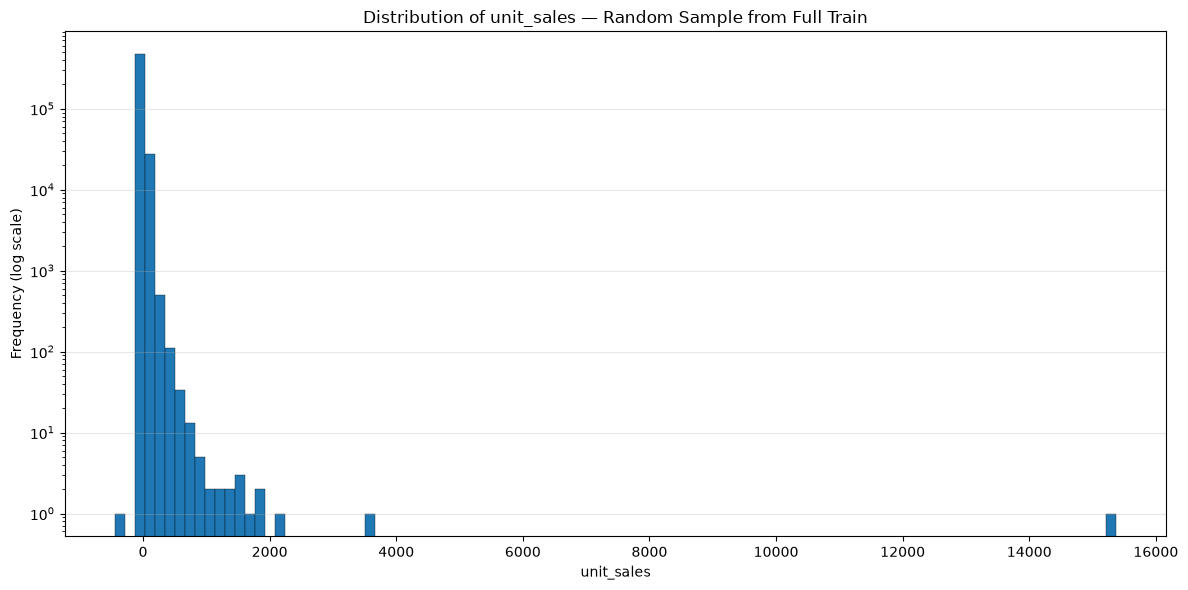

In [16]:
# Configuration
TRAIN_PATH = Path("../data/raw/train.csv")
CHUNK_SIZE = 1_000_000
SAMPLE_SIZE = 500_000
N_BINS = 100
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Pass 1: count rows in the entire file
chunk_sizes = []

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["unit_sales"],
    chunksize=CHUNK_SIZE
):
    chunk_sizes.append(len(chunk))

total_rows = sum(chunk_sizes)

# Allocate sample quotas proportionally to each chunk size.
# Largest-remainder allocation makes the total sample size exact
# when enough rows are available.
target_size = min(SAMPLE_SIZE, total_rows)
quotas_float = np.array(chunk_sizes, dtype=float) * target_size / total_rows
quotas = np.floor(quotas_float).astype(int)

remainder = target_size - quotas.sum()
if remainder > 0:
    order = np.argsort(-(quotas_float - quotas))
    quotas[order[:remainder]] += 1

# Pass 2: sample from every chunk
sample_parts = []

for i, chunk in enumerate(pd.read_csv(
    TRAIN_PATH,
    usecols=["unit_sales"],
    chunksize=CHUNK_SIZE
)):
    n = quotas[i]
    if n > 0:
        sample_parts.append(
            chunk["unit_sales"].dropna().sample(
                n=n,
                random_state=int(rng.integers(0, 2**31 - 1))
            )
        )

target_sample = pd.concat(sample_parts, ignore_index=True).dropna()

# Calculate percentiles
percentiles = [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 99.5, 99.9, 100]
quantile_table = target_sample.quantile(
    np.array(percentiles) / 100
).rename_axis("quantile").reset_index(name="unit_sales")

quantile_table["quantile"] = (
    quantile_table["quantile"] * 100
).map(lambda x: f"P{x:g}")

print(f"Total rows in train: {total_rows:,}")
print(f"Sample size: {len(target_sample):,}")
print(f"Sample min: {target_sample.min():,.4f}")
print(f"Sample max: {target_sample.max():,.4f}")
display(quantile_table)

# Histogram of the sampled target
plt.figure(figsize=(12, 6))
plt.hist(target_sample, bins=N_BINS, edgecolor="black", linewidth=0.25)
plt.yscale("log")
plt.title("Distribution of unit_sales — Random Sample from Full Train")
plt.xlabel("unit_sales")
plt.ylabel("Frequency (log scale)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Miền giá trị trên toàn bộ train

Đếm dòng âm, dòng bằng 0 và giá trị nhỏ nhất, lớn nhất.


Min: -15372.0
Max: 89440.0
Valid values: 125,497,040


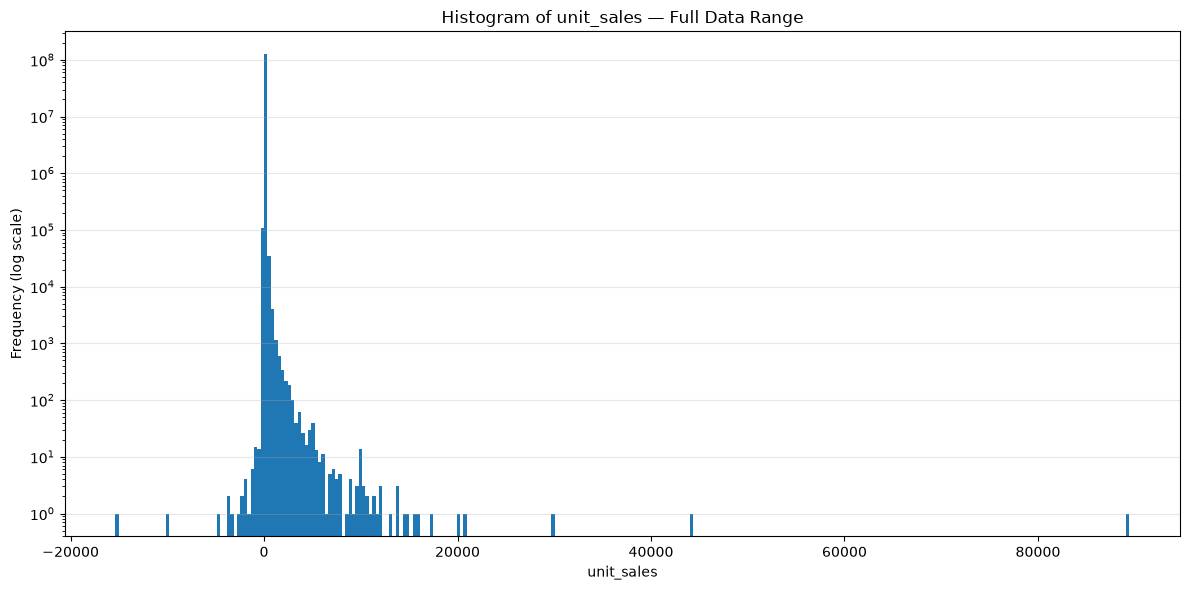

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_path = "../data/raw/train.csv"
chunk_size = 1_000_000
n_bins = 300

# Pass 1: tìm miền giá trị thực tế
min_val = np.inf
max_val = -np.inf
n_valid = 0

for chunk in pd.read_csv(
    train_path,
    usecols=["unit_sales"],
    chunksize=chunk_size
):
    s = chunk["unit_sales"].dropna()
    if not s.empty:
        min_val = min(min_val, s.min())
        max_val = max(max_val, s.max())
        n_valid += len(s)

print(f"Min: {min_val}")
print(f"Max: {max_val}")
print(f"Valid values: {n_valid:,}")

# Tạo bins bao phủ toàn bộ miền quan sát
if min_val == max_val:
    bin_edges = np.array([min_val - 0.5, max_val + 0.5])
else:
    bin_edges = np.linspace(min_val, max_val, n_bins + 1)

# Pass 2: đếm tần suất theo bins
counts = np.zeros(len(bin_edges) - 1, dtype=np.int64)

for chunk in pd.read_csv(
    train_path,
    usecols=["unit_sales"],
    chunksize=chunk_size
):
    values = chunk["unit_sales"].dropna().to_numpy()
    counts += np.histogram(values, bins=bin_edges)[0]

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(12, 6))

ax.stairs(counts, bin_edges, fill=True)
ax.set_yscale("log")
ax.set_title("Histogram of unit_sales — Full Data Range")
ax.set_xlabel("unit_sales")
ax.set_ylabel("Frequency (log scale)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 14. Khuyến mãi thiếu theo tháng

Kiểm tra thời điểm bắt đầu có dữ liệu `onpromotion`.


,month,total_rows,missing_rows,missing_pct
0,2013-01,1211964,1211964,100.0
1,2013-02,1160386,1160386,100.0
2,2013-03,1321927,1321927,100.0
3,2013-04,1284375,1284375,100.0
4,2013-05,1360917,1360917,100.0
5,2013-06,1353864,1353864,100.0
6,2013-07,1385579,1385579,100.0
7,2013-08,1421744,1421744,100.0
8,2013-09,1378438,1378438,100.0
9,2013-10,1428676,1428676,100.0


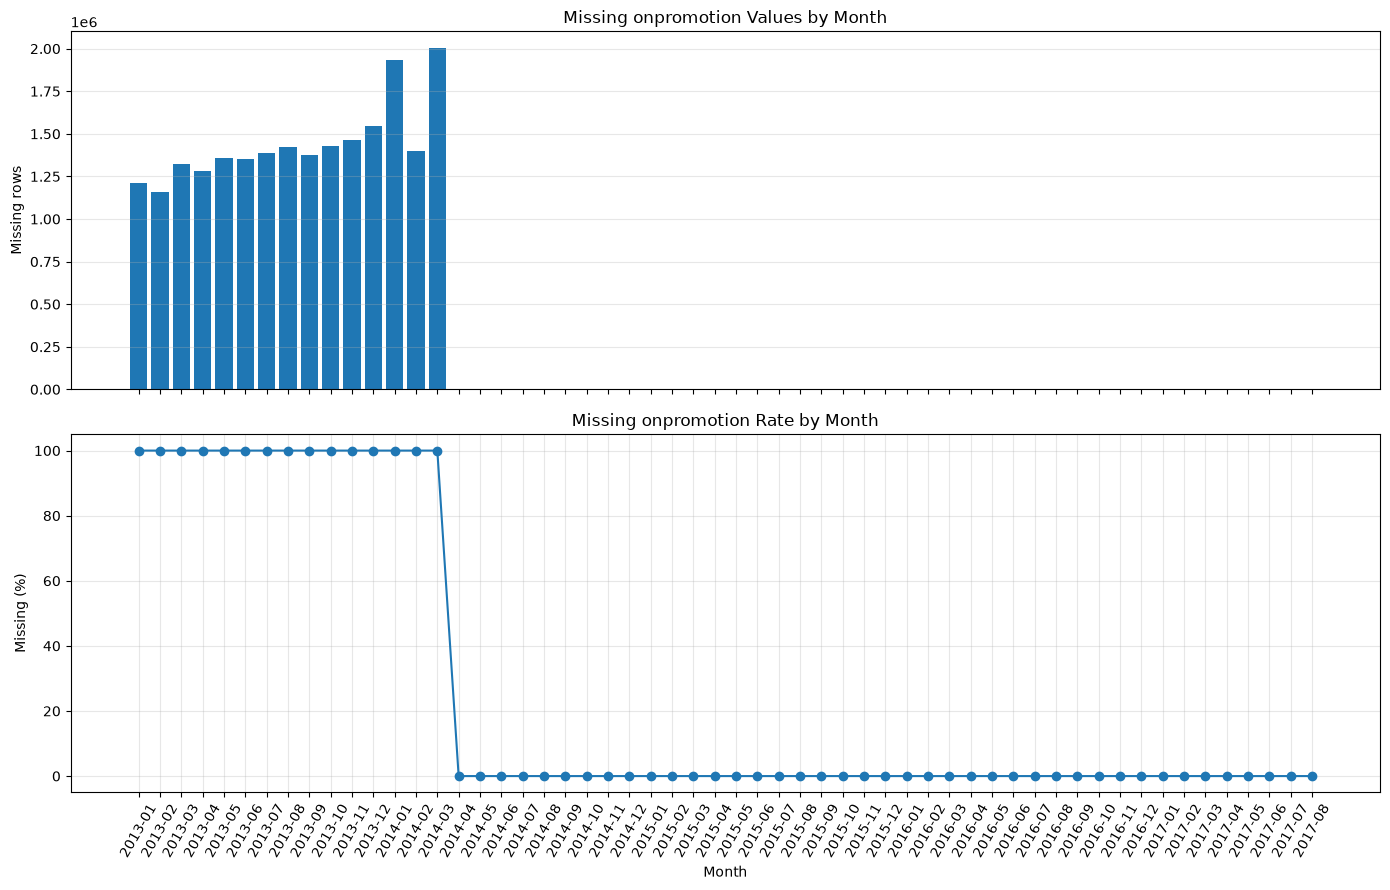

Top 10 months by missing rate:


,month,total_rows,missing_rows,missing_pct
0,2013-01,1211964,1211964,100.0
1,2013-02,1160386,1160386,100.0
2,2013-03,1321927,1321927,100.0
3,2013-04,1284375,1284375,100.0
4,2013-05,1360917,1360917,100.0
5,2013-06,1353864,1353864,100.0
6,2013-07,1385579,1385579,100.0
7,2013-08,1421744,1421744,100.0
8,2013-09,1378438,1378438,100.0
9,2013-10,1428676,1428676,100.0


Total missing: 21,657,651
Overall missing rate: 17.2575%


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

TRAIN_PATH = Path("../data/raw/train.csv")
CHUNK_SIZE = 500_000

monthly_stats = {}

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["date", "onpromotion"],
    dtype={"date": "string", "onpromotion": "string"},
    chunksize=CHUNK_SIZE,
    low_memory=False
):
    # Treat empty strings and whitespace as missing too
    promotion = chunk["onpromotion"].str.strip()
    missing = promotion.isna() | promotion.eq("")

    month = chunk["date"].str.slice(0, 7)

    temp = pd.DataFrame({
        "month": month,
        "missing": missing
    })

    grouped = temp.groupby("month", dropna=False)["missing"].agg(
        total_rows="size",
        missing_rows="sum"
    )

    for m, row in grouped.iterrows():
        if pd.isna(m):
            continue

        if m not in monthly_stats:
            monthly_stats[m] = [0, 0]

        monthly_stats[m][0] += int(row["total_rows"])
        monthly_stats[m][1] += int(row["missing_rows"])

monthly_df = pd.DataFrame.from_dict(
    monthly_stats,
    orient="index",
    columns=["total_rows", "missing_rows"]
)
monthly_df.index.name = "month"
monthly_df = monthly_df.sort_index()

monthly_df["missing_pct"] = (
    monthly_df["missing_rows"] / monthly_df["total_rows"] * 100
)

display(monthly_df.reset_index())

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].bar(monthly_df.index, monthly_df["missing_rows"])
axes[0].set_title("Missing onpromotion Values by Month")
axes[0].set_ylabel("Missing rows")
axes[0].grid(axis="y", alpha=0.3)

axes[1].plot(
    monthly_df.index,
    monthly_df["missing_pct"],
    marker="o"
)
axes[1].set_title("Missing onpromotion Rate by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Missing (%)")
axes[1].grid(alpha=0.3)

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

print("Top 10 months by missing rate:")
display(
    monthly_df.sort_values("missing_pct", ascending=False)
    .head(10)
    .reset_index()
)

print(f"Total missing: {monthly_df['missing_rows'].sum():,}")
print(
    f"Overall missing rate: "
    f"{monthly_df['missing_rows'].sum() / monthly_df['total_rows'].sum():.4%}"
)

## 15. Lịch sử các cặp trong train

Đếm các cặp cửa hàng–mặt hàng và khoảng xuất hiện.


In [19]:
TRAIN_PATH = Path("../data/raw/train.csv")
TEST_PATH = Path("../data/raw/test.csv")
CHUNK_SIZE = 1_000_000

# Collect unique items and store-item pairs from train
train_items = set()
train_pairs = set()

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["store_nbr", "item_nbr"],
    chunksize=CHUNK_SIZE
):
    train_items.update(chunk["item_nbr"].dropna().unique())

    train_pairs.update(
        chunk[["store_nbr", "item_nbr"]]
        .drop_duplicates()
        .itertuples(index=False, name=None)
    )

print(f"Unique train items: {len(train_items):,}")
print(f"Unique train (store, item) pairs: {len(train_pairs):,}")

# Collect unique items and pairs from test
test_items = set()
test_pairs = set()

for chunk in pd.read_csv(
    TEST_PATH,
    usecols=["store_nbr", "item_nbr"],
    chunksize=CHUNK_SIZE
):
    test_items.update(chunk["item_nbr"].dropna().unique())

    test_pairs.update(
        chunk[["store_nbr", "item_nbr"]]
        .drop_duplicates()
        .itertuples(index=False, name=None)
    )

# Cold-start sets
cold_items = test_items - train_items
cold_pairs = test_pairs - train_pairs

# Summary
summary = pd.DataFrame({
    "metric": [
        "Unique items in test",
        "Items also seen in train",
        "Cold-start items in test",
        "Unique (store, item) pairs in test",
        "Pairs also seen in train",
        "Cold-start pairs in test",
    ],
    "count": [
        len(test_items),
        len(test_items & train_items),
        len(cold_items),
        len(test_pairs),
        len(test_pairs & train_pairs),
        len(cold_pairs),
    ]
})

display(summary)

print(
    f"Cold-start item rate: "
    f"{len(cold_items) / len(test_items):.4%}"
    if test_items else "No items in test."
)
print(
    f"Cold-start pair rate: "
    f"{len(cold_pairs) / len(test_pairs):.4%}"
    if test_pairs else "No pairs in test."
)

# Optional: inspect IDs for diagnosis
print("Cold-start item IDs:", sorted(cold_items)[:30])
print("Cold-start pairs:", sorted(cold_pairs)[:30])

Unique train items: 4,036
Unique train (store, item) pairs: 174,685


,metric,count
0,Unique items in test,3901
1,Items also seen in train,3841
2,Cold-start items in test,60
3,"Unique (store, item) pairs in test",210654
4,Pairs also seen in train,166213
5,Cold-start pairs in test,44441


Cold-start item rate: 1.5381%
Cold-start pair rate: 21.0967%
Cold-start item IDs: [np.int64(313094), np.int64(1464607), np.int64(1467088), np.int64(1467093), np.int64(2015646), np.int64(2109969), np.int64(2112280), np.int64(2112303), np.int64(2112461), np.int64(2112462), np.int64(2112607), np.int64(2117783), np.int64(2118397), np.int64(2120180), np.int64(2120216), np.int64(2120506), np.int64(2120681), np.int64(2120768), np.int64(2121319), np.int64(2124705), np.int64(2125814), np.int64(2126696), np.int64(2127024), np.int64(2127069), np.int64(2127175), np.int64(2127206), np.int64(2127544), np.int64(2127651), np.int64(2127733), np.int64(2127825)]
Cold-start pairs: [(1, 103501), (1, 105576), (1, 108833), (1, 119193), (1, 129759), (1, 155500), (1, 168931), (1, 172995), (1, 179579), (1, 218728), (1, 220432), (1, 255198), (1, 255199), (1, 260628), (1, 264305), (1, 268446), (1, 279125), (1, 302824), (1, 305074), (1, 305234), (1, 305237), (1, 310790), (1, 313094), (1, 320681), (1, 329364), (1, 

## 16. Cặp mới trong test

Đối chiếu khóa test với lịch sử train. Tách cặp mới có item đã biết và item chưa từng xuất hiện.


In [20]:
import pandas as pd

# Configuration
TRAIN_PATH = "../data/raw/train.csv"
TEST_PATH = "../data/raw/test.csv"
CHUNK_SIZE = 1_000_000

# 1. Thu thập các mặt hàng và cặp (store, item) xuất hiện trong train
train_items = set()
train_store_item_pairs = set()

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["store_nbr", "item_nbr"],
    dtype={
        "store_nbr": "int16",
        "item_nbr": "int32",
    },
    chunksize=CHUNK_SIZE,
):
    train_items.update(chunk["item_nbr"].unique())

    unique_pairs = chunk[["store_nbr", "item_nbr"]].drop_duplicates()
    train_store_item_pairs.update(
        zip(unique_pairs["store_nbr"], unique_pairs["item_nbr"])
    )

# 2. Đọc test và lấy các mặt hàng/cặp duy nhất
test = pd.read_csv(
    TEST_PATH,
    usecols=["store_nbr", "item_nbr"],
    dtype={
        "store_nbr": "int16",
        "item_nbr": "int32",
    },
)

test_items = set(test["item_nbr"].unique())

test_pairs = set(
    zip(test["store_nbr"], test["item_nbr"])
)

# 3. Xác định cold-start
cold_start_items = test_items - train_items
cold_start_pairs = test_pairs - train_store_item_pairs

# 4. Báo cáo
print("=== COLD-START ANALYSIS ===")

print("\n[Item level]")
print(f"Unique items in train: {len(train_items):,}")
print(f"Unique items in test: {len(test_items):,}")
print(f"Cold-start items: {len(cold_start_items):,}")
print(
    "Cold-start item rate in test: "
    f"{len(cold_start_items) / len(test_items):.4%}"
    if test_items else "Cold-start item rate: N/A"
)

print("\n[Store-item pair level]")
print(f"Unique (store, item) pairs in train: {len(train_store_item_pairs):,}")
print(f"Unique (store, item) pairs in test: {len(test_pairs):,}")
print(f"Cold-start pairs: {len(cold_start_pairs):,}")
print(
    "Cold-start pair rate in test: "
    f"{len(cold_start_pairs) / len(test_pairs):.4%}"
    if test_pairs else "Cold-start pair rate: N/A"
)

# 5. Hiển thị mã mặt hàng chưa từng xuất hiện trong train
print("\nCold-start item_nbr values:")
print(sorted(cold_start_items))

# Hiển thị một số cặp cold-start để kiểm tra
cold_start_pairs_df = pd.DataFrame(
    sorted(cold_start_pairs),
    columns=["store_nbr", "item_nbr"],
)

print("\nSample cold-start store-item pairs:")
display(cold_start_pairs_df.head(20))

=== COLD-START ANALYSIS ===

[Item level]
Unique items in train: 4,036
Unique items in test: 3,901
Cold-start items: 60
Cold-start item rate in test: 1.5381%

[Store-item pair level]
Unique (store, item) pairs in train: 174,685
Unique (store, item) pairs in test: 210,654
Cold-start pairs: 44,441
Cold-start pair rate in test: 21.0967%

Cold-start item_nbr values:
[np.int32(313094), np.int32(1464607), np.int32(1467088), np.int32(1467093), np.int32(2015646), np.int32(2109969), np.int32(2112280), np.int32(2112303), np.int32(2112461), np.int32(2112462), np.int32(2112607), np.int32(2117783), np.int32(2118397), np.int32(2120180), np.int32(2120216), np.int32(2120506), np.int32(2120681), np.int32(2120768), np.int32(2121319), np.int32(2124705), np.int32(2125814), np.int32(2126696), np.int32(2127024), np.int32(2127069), np.int32(2127175), np.int32(2127206), np.int32(2127544), np.int32(2127651), np.int32(2127733), np.int32(2127825), np.int32(2127921), np.int32(2127992), np.int32(2128628), np.int32

,store_nbr,item_nbr
0,1,103501
1,1,105576
2,1,108833
3,1,119193
4,1,129759
5,1,155500
6,1,168931
7,1,172995
8,1,179579
9,1,218728


## 17. Doanh số ngày 15 và cuối tháng

So sánh doanh số theo ngày trong tháng. Ngày 15 chưa có mức tăng rõ và ổn định; cuối tháng có tín hiệu tăng. Chưa đủ bằng chứng để quy nguyên nhân cho ngày trả lương.


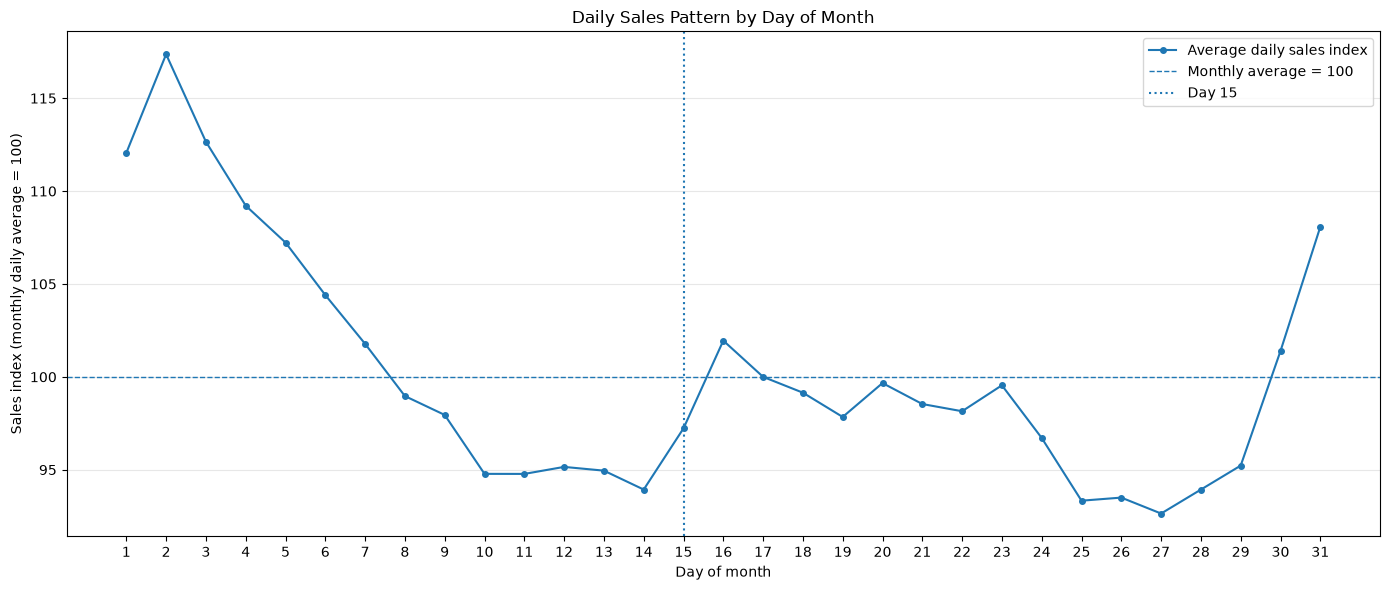

=== Sales comparison ===


,mean_daily_sales,mean_sales_index,n_days
period_group,,,
Other days,638305.6250,100.135,1463
Day 15,621445.4375,97.228,56
Last 3 days,636170.6875,99.745,165


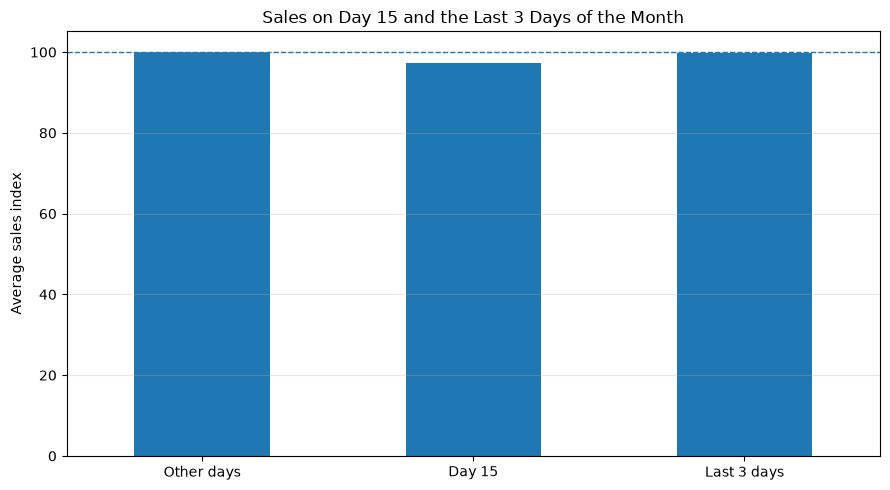

In [21]:
# Configuration
TRAIN_PATH = "../data/raw/train.csv"
CHUNK_SIZE = 1_000_000

# Pass 1: tính tổng unit_sales theo từng ngày
daily_parts = []

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=["date", "unit_sales"],
    dtype={"unit_sales": "float32"},
    parse_dates=["date"],
    chunksize=CHUNK_SIZE,
):
    daily = (
        chunk.groupby("date", as_index=False)["unit_sales"]
        .sum()
    )
    daily_parts.append(daily)

# Gộp các kết quả từ chunks
daily_sales = (
    pd.concat(daily_parts, ignore_index=True)
    .groupby("date", as_index=False)["unit_sales"]
    .sum()
    .sort_values("date")
    .reset_index(drop=True)
)

# 2. Tạo đặc trưng ngày trong tháng
daily_sales["day_of_month"] = daily_sales["date"].dt.day
daily_sales["days_in_month"] = daily_sales["date"].dt.days_in_month

# Ngày cuối tháng = ngày lịch cuối cùng của tháng
daily_sales["is_last_day"] = (
    daily_sales["day_of_month"] == daily_sales["days_in_month"]
)

# Ba ngày cuối tháng: ngày cuối, áp cuối và trước áp cuối
daily_sales["is_last_3_days"] = (
    daily_sales["day_of_month"] >= daily_sales["days_in_month"] - 2
)

daily_sales["is_day_15"] = daily_sales["day_of_month"] == 15

# 3. Chuẩn hóa theo mức doanh số trung bình của từng tháng
# Index = 100 nghĩa là doanh số ngày đó bằng trung bình ngày của tháng.
daily_sales["year_month"] = daily_sales["date"].dt.to_period("M")

monthly_mean = daily_sales.groupby("year_month")["unit_sales"].transform("mean")

daily_sales["sales_index"] = np.where(
    monthly_mean != 0,
    daily_sales["unit_sales"] / monthly_mean * 100,
    np.nan,
)

# 4. Tổng hợp theo ngày trong tháng
day_profile = (
    daily_sales.groupby("day_of_month")
    .agg(
        mean_daily_sales=("unit_sales", "mean"),
        mean_sales_index=("sales_index", "mean"),
        n_days=("date", "count"),
    )
    .reindex(range(1, 32))
)

# 5. Vẽ biểu đồ: chỉ số doanh số trung bình theo ngày trong tháng
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    day_profile.index,
    day_profile["mean_sales_index"],
    marker="o",
    markersize=4,
    linewidth=1.5,
    label="Average daily sales index",
)

ax.axhline(100, linestyle="--", linewidth=1, label="Monthly average = 100")
ax.axvline(15, linestyle=":", linewidth=1.5, label="Day 15")

ax.set_xticks(range(1, 32))
ax.set_xlabel("Day of month")
ax.set_ylabel("Sales index (monthly daily average = 100)")
ax.set_title("Daily Sales Pattern by Day of Month")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# 6. So sánh ngày 15, ba ngày cuối tháng và các ngày còn lại
daily_sales["period_group"] = np.select(
    [
        daily_sales["is_day_15"],
        daily_sales["is_last_3_days"],
    ],
    [
        "Day 15",
        "Last 3 days",
    ],
    default="Other days",
)

comparison = (
    daily_sales.groupby("period_group")
    .agg(
        mean_daily_sales=("unit_sales", "mean"),
        mean_sales_index=("sales_index", "mean"),
        n_days=("date", "count"),
    )
    .reindex(["Other days", "Day 15", "Last 3 days"])
)

print("=== Sales comparison ===")
display(comparison.round(3))

# 7. Vẽ biểu đồ so sánh chỉ số
fig, ax = plt.subplots(figsize=(9, 5))

comparison["mean_sales_index"].plot(
    kind="bar",
    ax=ax,
    rot=0,
)

ax.axhline(100, linestyle="--", linewidth=1)
ax.set_ylabel("Average sales index")
ax.set_xlabel("")
ax.set_title("Sales on Day 15 and the Last 3 Days of the Month")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Các cột được báo là “extra” cần đối chiếu với danh sách schema đang dùng. Danh sách thiếu cột khai báo không có nghĩa dữ liệu chứa cột sai.


## 18. Chất lượng dữ liệu

Kiểm tra missing, dòng trùng và giá trị ngoài miền dự kiến.


In [22]:
def aggregate_missing(path, chunksize=DEFAULT_CHUNK_SIZE):
    total_rows = 0
    missing = None

    for chunk in pd.read_csv(path, chunksize=chunksize):
        total_rows += len(chunk)
        counts = chunk.isna().sum()

        if missing is None:
            missing = counts.astype("int64")
        else:
            missing = missing.add(counts, fill_value=0).astype("int64")

    result = pd.DataFrame({
        "missing_count": missing,
        "missing_pct": missing / total_rows * 100,
    }).sort_values("missing_count", ascending=False)

    return result

missing_train = aggregate_missing(RAW_DATA_DIR / "train.csv")
missing_train

,missing_count,missing_pct
onpromotion,21657651,17.257499
id,0,0.000000
date,0,0.000000
store_nbr,0,0.000000
item_nbr,0,0.000000
unit_sales,0,0.000000


In [23]:
reference_missing = {}

for filename, df in small_tables.items():
    reference_missing[filename] = (
        pd.DataFrame({
            "missing_count": df.isna().sum(),
            "missing_pct": df.isna().mean() * 100,
        })
        .sort_values("missing_count", ascending=False)
    )

for filename, result in reference_missing.items():
    print("=" * 80)
    print(filename)
    display(result)

stores.csv


,missing_count,missing_pct
store_nbr,0,0.0
city,0,0.0
state,0,0.0
type,0,0.0
cluster,0,0.0


items.csv


,missing_count,missing_pct
item_nbr,0,0.0
family,0,0.0
class,0,0.0
perishable,0,0.0


oil.csv


,missing_count,missing_pct
dcoilwtico,43,3.530378
date,0,0.000000


holidays_events.csv


,missing_count,missing_pct
date,0,0.0
type,0,0.0
locale,0,0.0
locale_name,0,0.0
description,0,0.0
transferred,0,0.0


transactions.csv


,missing_count,missing_pct
date,0,0.0
store_nbr,0,0.0
transactions,0,0.0


`onpromotion` thiếu tập trung trước tháng 04/2014. Đây là thiếu theo giai đoạn, không nên điền tất cả thành False.

Giá dầu thiếu một phần ngày giao dịch và không có nhiều ngày cuối tuần. Cách điền cần giữ đúng thứ tự thời gian.


In [24]:
duplicate_summary = []

for filename, df in small_tables.items():
    duplicate_summary.append({
        "file": filename,
        "duplicate_rows": int(df.duplicated().sum()),
        "rows": len(df),
    })

pd.DataFrame(duplicate_summary)

,file,duplicate_rows,rows
0,stores.csv,0,54
1,items.csv,0,4100
2,oil.csv,0,1218
3,holidays_events.csv,0,350
4,transactions.csv,0,83488


In [25]:
# Chunk-local duplicate check for train.csv.
# This does not prove that duplicates cannot occur across chunk boundaries.
def chunk_duplicate_check(path, chunksize=DEFAULT_CHUNK_SIZE):
    total_duplicate_rows = 0
    total_rows = 0

    for chunk in pd.read_csv(path, chunksize=chunksize):
        total_duplicate_rows += int(chunk.duplicated().sum())
        total_rows += len(chunk)

    return {
        "rows_checked": total_rows,
        "duplicate_rows_within_chunks": total_duplicate_rows,
    }

train_duplicate_result = chunk_duplicate_check(RAW_DATA_DIR / "train.csv")
train_duplicate_result

{'rows_checked': 125497040, 'duplicate_rows_within_chunks': 0}

Kiểm tra trùng trong từng chunk chưa đủ để loại trừ trùng giữa các chunk. Notebook 02 kiểm tra thêm thứ tự khóa và biên chunk.


In [26]:
invalid_stats = {
    "unit_sales_negative": 0,
    "unit_sales_zero": 0,
    "store_nbr_nonpositive": 0,
    "item_nbr_nonpositive": 0,
    "onpromotion_null": 0,
}

total_rows = 0

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["unit_sales", "store_nbr", "item_nbr", "onpromotion"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    total_rows += len(chunk)
    invalid_stats["unit_sales_negative"] += int((chunk["unit_sales"] < 0).sum())
    invalid_stats["unit_sales_zero"] += int((chunk["unit_sales"] == 0).sum())    
    invalid_stats["store_nbr_nonpositive"] += int((chunk["store_nbr"] <= 0).sum())
    invalid_stats["item_nbr_nonpositive"] += int((chunk["item_nbr"] <= 0).sum())
    invalid_stats["onpromotion_null"] += int(chunk["onpromotion"].isna().sum())

invalid_df = pd.DataFrame({"count": invalid_stats})
invalid_df["pct_of_train"] = invalid_df["count"] / total_rows * 100
invalid_df

,count,pct_of_train
unit_sales_negative,7795,0.006211
unit_sales_zero,0,0.000000
store_nbr_nonpositive,0,0.000000
item_nbr_nonpositive,0,0.000000
onpromotion_null,21657651,17.257499


Giá trị âm, số thực và doanh số lớn chưa đủ để kết luận là lỗi. Cần xem theo mặt hàng, cửa hàng và ngày. Các dòng này được giữ lại ở cleaning.


In [27]:
unique_values = {
    "store_nbr": set(),
    "item_nbr": set(),
    "date": set(),
}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["store_nbr", "item_nbr", "date"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    unique_values["store_nbr"].update(chunk["store_nbr"].dropna().unique().tolist())
    unique_values["item_nbr"].update(chunk["item_nbr"].dropna().unique().tolist())
    unique_values["date"].update(chunk["date"].dropna().astype(str).unique().tolist())

cardinality_df = pd.DataFrame({
    "column": list(unique_values.keys()),
    "unique_values": [len(v) for v in unique_values.values()],
})

cardinality_df

,column,unique_values
0,store_nbr,54
1,item_nbr,4036
2,date,1684


## 19. Khóa tham chiếu

Đối chiếu cửa hàng và mặt hàng trong train/test với các bảng metadata.


In [28]:
def train_unique_keys(columns, chunksize=DEFAULT_CHUNK_SIZE):
    unique = {col: set() for col in columns}

    for chunk in pd.read_csv(
        RAW_DATA_DIR / "train.csv",
        usecols=columns,
        chunksize=chunksize,
    ):
        for col in columns:
            unique[col].update(chunk[col].dropna().unique().tolist())

    return unique

train_keys = train_unique_keys(["store_nbr", "item_nbr", "date"])

relationship_results = []

if "stores.csv" in small_tables and "store_nbr" in small_tables["stores.csv"].columns:
    store_keys = set(small_tables["stores.csv"]["store_nbr"].dropna().unique())
    missing_stores = train_keys["store_nbr"] - store_keys

    relationship_results.append({
        "relationship": "train.store_nbr -> stores.store_nbr",
        "missing_reference_keys": len(missing_stores),
        "status": "OK" if not missing_stores else "CHECK",
    })

if "items.csv" in small_tables and "item_nbr" in small_tables["items.csv"].columns:
    item_keys = set(small_tables["items.csv"]["item_nbr"].dropna().unique())
    missing_items = train_keys["item_nbr"] - item_keys

    relationship_results.append({
        "relationship": "train.item_nbr -> items.item_nbr",
        "missing_reference_keys": len(missing_items),
        "status": "OK" if not missing_items else "CHECK",
    })

pd.DataFrame(relationship_results)

,relationship,missing_reference_keys,status
0,train.store_nbr -> stores.store_nbr,0,OK
1,train.item_nbr -> items.item_nbr,0,OK


In [29]:
date_ranges = []

for filename, df in small_tables.items():
    if "date" in df.columns:
        dates = pd.to_datetime(df["date"], errors="coerce")
        date_ranges.append({
            "dataset": filename,
            "min_date": dates.min(),
            "max_date": dates.max(),
            "invalid_dates": int(dates.isna().sum()),
        })

train_min = None
train_max = None
train_invalid_dates = 0

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["date"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    dates = pd.to_datetime(chunk["date"], errors="coerce")
    train_invalid_dates += int(dates.isna().sum())

    cmin = dates.min()
    cmax = dates.max()

    if train_min is None or cmin < train_min:
        train_min = cmin
    if train_max is None or cmax > train_max:
        train_max = cmax

date_ranges.append({
    "dataset": "train.csv",
    "min_date": train_min,
    "max_date": train_max,
    "invalid_dates": train_invalid_dates,
})

pd.DataFrame(date_ranges).sort_values("min_date")

,dataset,min_date,max_date,invalid_dates
1,holidays_events.csv,2012-03-02,2017-12-26,0
0,oil.csv,2013-01-01,2017-08-31,0
2,transactions.csv,2013-01-01,2017-08-15,0
3,train.csv,2013-01-01,2017-08-15,0


Các khóa cửa hàng và mặt hàng trong train đều có metadata tương ứng. Khi ghép bảng ngày lễ, không coi riêng `date` là khóa duy nhất.


## 20. Khoảng thời gian

Kiểm tra ngày đầu, ngày cuối, ngày thiếu và khoảng cách giữa train với test.


In [30]:
train_test_ranges = []

for filename in ["train.csv", "test.csv"]:
    path = RAW_DATA_DIR / filename
    if not path.exists():
        continue

    min_date = None
    max_date = None

    for chunk in pd.read_csv(path, usecols=["date"], chunksize=DEFAULT_CHUNK_SIZE):
        dates = pd.to_datetime(chunk["date"], errors="coerce")

        cmin = dates.min()
        cmax = dates.max()

        if min_date is None or cmin < min_date:
            min_date = cmin
        if max_date is None or cmax > max_date:
            max_date = cmax

    train_test_ranges.append({
        "dataset": filename,
        "min_date": min_date,
        "max_date": max_date,
    })

train_test_ranges_df = pd.DataFrame(train_test_ranges)
train_test_ranges_df

,dataset,min_date,max_date
0,train.csv,2013-01-01,2017-08-15
1,test.csv,2017-08-16,2017-08-31


In [31]:
train_dates = pd.to_datetime(
    pd.Series(list(unique_values["date"])),
    errors="coerce"
).dropna()

train_dates = pd.DatetimeIndex(sorted(train_dates.unique()))

if len(train_dates) > 0:
    expected_dates = pd.date_range(train_dates.min(), train_dates.max(), freq="D")
    missing_calendar_dates = expected_dates.difference(train_dates)

    print("Observed unique dates:", len(train_dates))
    print("Expected calendar days:", len(expected_dates))
    print("Missing calendar dates:", len(missing_calendar_dates))

    if len(missing_calendar_dates) > 0:
        print("First missing dates:", missing_calendar_dates[:20].tolist())

Observed unique dates: 1684
Expected calendar days: 1688
Missing calendar dates: 4
First missing dates: [Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


In [32]:
daily_sales = {}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["date", "unit_sales"],
    parse_dates=["date"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("date")["unit_sales"].sum()

    for date, value in grouped.items():
        daily_sales[date] = daily_sales.get(date, 0.0) + float(value)

daily_sales_df = (
    pd.Series(daily_sales, name="unit_sales")
    .sort_index()
    .to_frame()
)

daily_sales_df.head()

,unit_sales
2013-01-01,2511.619
2013-01-02,496092.418
2013-01-03,361429.231
2013-01-04,354459.677
2013-01-05,477350.121


Train kết thúc ngày 15/08/2017; test từ 16 đến 31/08/2017. Bốn ngày thiếu trong train là 25/12 của các năm 2013–2016. Không tự coi các ngày vắng toàn hệ thống là doanh số 0.


## 21. Kiểm tra target

Thống kê phân phối và các trường hợp đặc biệt của `unit_sales`.


In [33]:

SAMPLE_FRACTION = 0.001  # Lấy mẫu kỳ vọng khoảng 0.1% số dòng
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

target_stats = {
    "count": 0,
    "sum": 0.0,
    "sum_sq": 0.0,
    "min": np.inf,
    "max": -np.inf,
    "zero_count": 0,
    "negative_count": 0,
}

target_sample_parts = []

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=[TARGET_COLUMN],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    s = chunk[TARGET_COLUMN].dropna()

    # Thống kê trên TOÀN BỘ dữ liệu
    target_stats["count"] += len(s)
    target_stats["sum"] += float(s.sum())
    target_stats["sum_sq"] += float((s ** 2).sum())
    target_stats["min"] = min(target_stats["min"], float(s.min()))
    target_stats["max"] = max(target_stats["max"], float(s.max()))
    target_stats["zero_count"] += int((s == 0).sum())
    target_stats["negative_count"] += int((s < 0).sum())

    # Lấy mẫu ngẫu nhiên từ TỪNG chunk, bao gồm tất cả các chunk
    mask = rng.random(len(s)) < SAMPLE_FRACTION
    sampled = s.iloc[np.flatnonzero(mask)]

    if not sampled.empty:
        target_sample_parts.append(sampled)

target_count = target_stats["count"]
target_mean = target_stats["sum"] / target_count
target_variance = (
    target_stats["sum_sq"] / target_count - target_mean ** 2
)

target_summary = pd.Series({
    "count": target_count,
    "mean": target_mean,
    "std": math.sqrt(max(target_variance, 0)),
    "min": target_stats["min"],
    "max": target_stats["max"],
    "zero_count": target_stats["zero_count"],
    "zero_pct": target_stats["zero_count"] / target_count * 100,
    "negative_count": target_stats["negative_count"],
    "negative_pct": target_stats["negative_count"] / target_count * 100,
})

target_summary


count             1.254970e+08
mean              8.554865e+00
std               2.360515e+01
min              -1.537200e+04
max               8.944000e+04
zero_count        0.000000e+00
zero_pct          0.000000e+00
negative_count    7.795000e+03
negative_pct      6.211302e-03
dtype: float64

In [34]:
target_sample = pd.concat(target_sample_parts, ignore_index=True)

print(f"Sample size: {len(target_sample):,}")
print(f"Sampling fraction configured: {SAMPLE_FRACTION:.2%}")

target_quantiles = target_sample.quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

target_quantiles

Sample size: 125,580
Sampling fraction configured: 0.10%


0.500      4.000
0.750      9.000
0.900     18.000
0.950     29.000
0.990     72.000
0.999    213.421
Name: unit_sales, dtype: float64

Train không có dòng `unit_sales = 0`, nhưng có 7.795 dòng âm. Phân phối lệch phải mạnh, nên dùng thêm phân vị và thang log khi xem biểu đồ.


## 22. Đối chiếu cache

So sánh thống kê từ cache với các kết quả đã tính trước đó.


In [35]:
import math

daily_cache = eda["daily"]
checks = {
    "rows (cache) == target_stats['count']": int(daily_cache["rows"].sum()) == int(target_stats["count"]),
    "negative rows (cache) == target_stats['negative_count']": int(daily_cache["neg_rows"].sum()) == int(target_stats["negative_count"]),
    "sum unit_sales (cache) ≈ target_stats['sum']": math.isclose(float(daily_cache["sales"].sum()), target_stats["sum"], rel_tol=1e-9),
    "số ngày (cache) == 1 684-ngày đã quan sát ở mục 5": len(daily_cache) == len(train_dates),
    "promo thiếu (cache) == missing_train['onpromotion']": int(daily_cache["promo_missing_rows"].sum()) == int(missing_train.loc["onpromotion", "missing_count"]),
}
display(pd.Series(checks, name="OK").to_frame())
assert all(checks.values()), "Cache không khớp kết quả quét trực tiếp; đặt FORCE_REBUILD_CACHE = True và chạy lại."
print("Cache khớp các thống kê exact đã tính trước đó.")

,OK
rows (cache) == target_stats['count'],True
negative rows (cache) == target_stats['negative_count'],True
sum unit_sales (cache) ≈ target_stats['sum'],True
số ngày (cache) == 1 684-ngày đã quan sát ở mục 5,True
promo thiếu (cache) == missing_train['onpromotion'],True


Cache khớp các thống kê exact đã tính trước đó.


## 23. Các nhóm phân tích

Xem doanh số theo thời gian, cửa hàng, mặt hàng, khuyến mãi, giá dầu và ngày lễ.


## 24. Phân phối doanh số

Xem histogram và các phân vị để nhận biết đuôi phân phối.


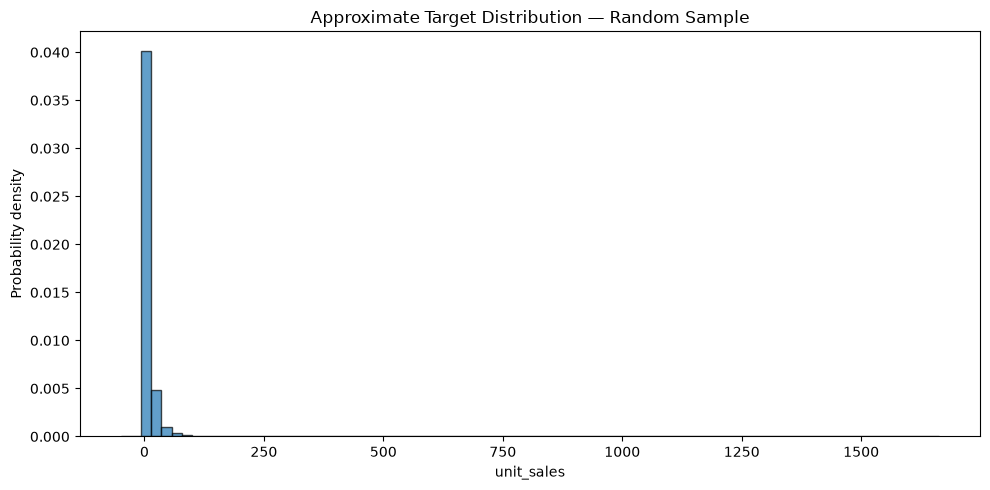

In [36]:
plt.figure(figsize=(10, 5))
plt.hist(
    target_sample,
    bins=80,
    density=True,
    edgecolor="black",
    alpha=0.7,
)
plt.xlabel("unit_sales")
plt.ylabel("Probability density")
plt.title("Approximate Target Distribution — Random Sample")
plt.tight_layout()
plt.show()


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_24188\3865279283.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target_sample, vert=False, showfliers=False)


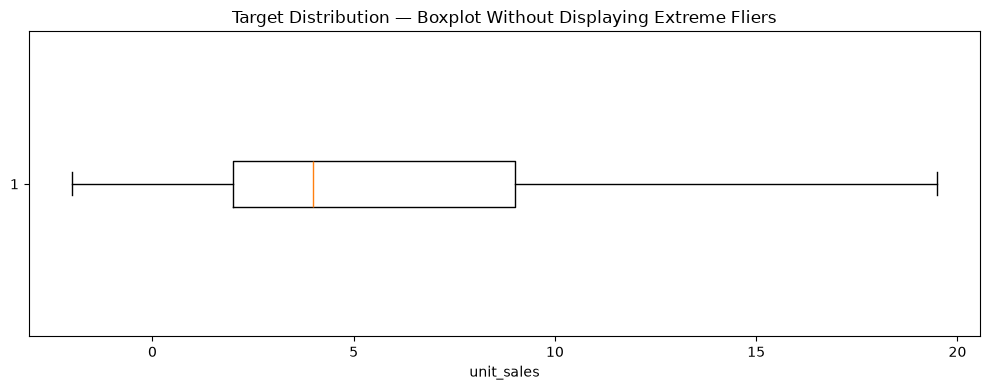

In [37]:
plt.figure(figsize=(10, 4))
plt.boxplot(target_sample, vert=False, showfliers=False)
plt.xlabel("unit_sales")
plt.title("Target Distribution — Boxplot Without Displaying Extreme Fliers")
plt.tight_layout()
plt.show()

Doanh số có đuôi phải dài: trung vị khoảng 4, nhưng giá trị lớn nhất là 89.440. Không dùng riêng trung bình để mô tả một dòng bán thông thường. Thang log giúp nhìn phần lớn dữ liệu rõ hơn.


## 25. Doanh số theo thời gian

Xem tổng doanh số theo ngày, tuần, tháng và ngày trong tháng.


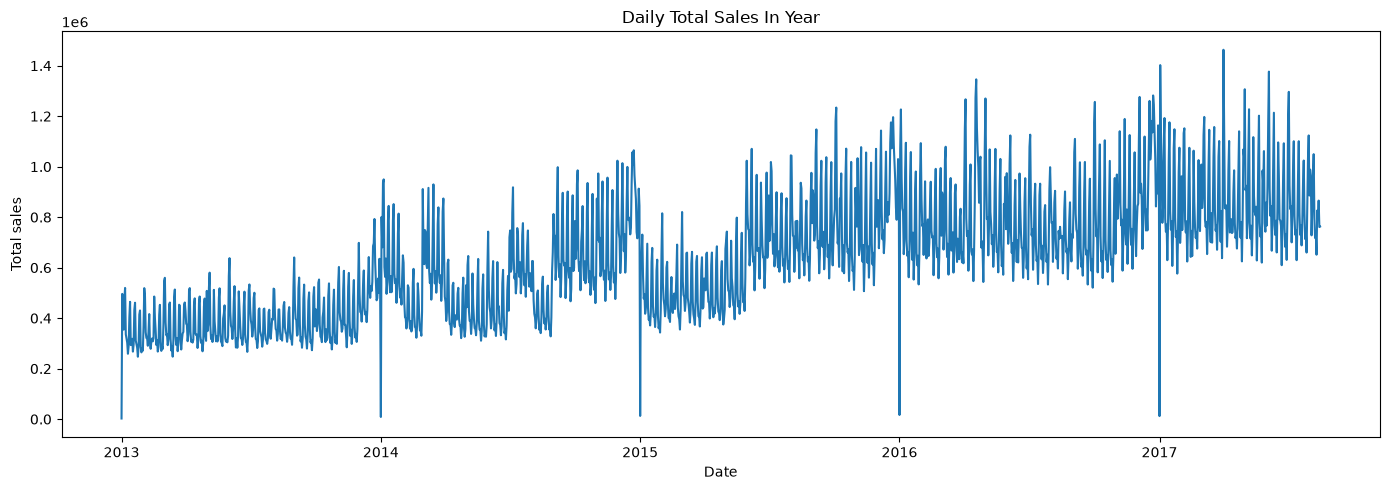

In [38]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales_df.index, daily_sales_df["unit_sales"])
plt.xlabel("Date")
plt.ylabel("Total sales")
plt.title("Daily Total Sales In Year")
plt.tight_layout()
plt.show()

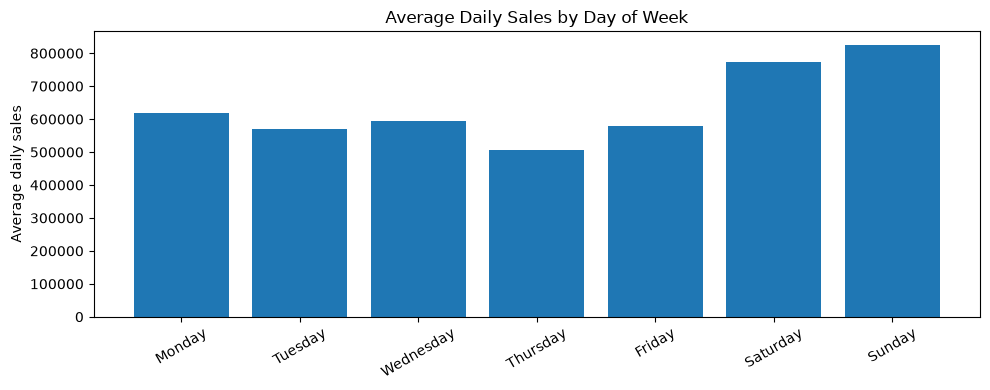

In [39]:
daily_eda = daily_sales_df.copy()
daily_eda["day_of_week"] = daily_eda.index.day_name()
daily_eda["month"] = daily_eda.index.month
daily_eda["year"] = daily_eda.index.year

dow_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

dow_sales = daily_eda.groupby("day_of_week")["unit_sales"].mean().reindex(dow_order)

plt.figure(figsize=(10, 4))
plt.bar(dow_sales.index, dow_sales.values)
plt.xticks(rotation=30)
plt.ylabel("Average daily sales")
plt.title("Average Daily Sales by Day of Week")
plt.tight_layout()
plt.show()

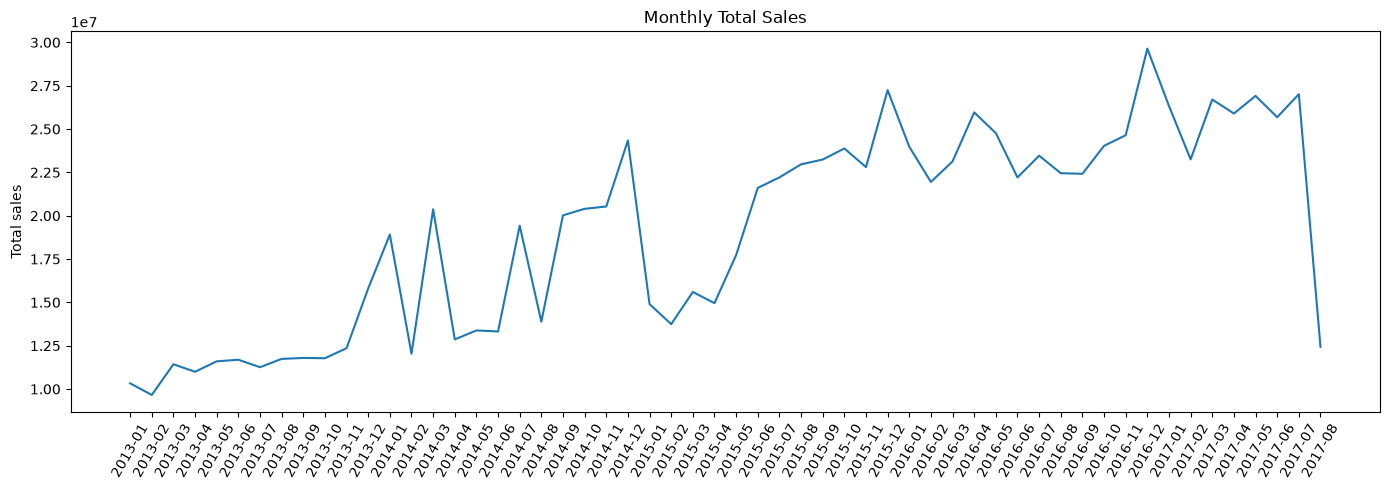

In [40]:
monthly_sales = daily_eda.groupby(
    [daily_eda.index.year, daily_eda.index.month]
)["unit_sales"].sum()

monthly_sales.index = [
    f"{year}-{month:02d}" for year, month in monthly_sales.index
]

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.xticks(rotation=60)
plt.ylabel("Total sales")
plt.title("Monthly Total Sales")
plt.tight_layout()
plt.show()

Cuối tuần có tổng doanh số cao hơn ngày thường; tháng 12 thường có đỉnh. Tháng 08/2017 trong train chỉ có 15 ngày nên không so sánh tổng tháng này với tháng đầy đủ.

Đầu tháng và cuối tháng có tín hiệu tăng. Ngày 15 gần mức trung bình, chưa có mức tăng ổn định.

Tổng doanh số tháng tương quan 0,965 với số dòng ghi nhận. Xu hướng tổng doanh số có thể chịu ảnh hưởng lớn của độ phủ dữ liệu; chưa thể quy toàn bộ thay đổi cho nhu cầu.


## 26. Doanh số theo cửa hàng

Thống kê mức bán và tỷ trọng của từng cửa hàng.


In [41]:
store_sales = {}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["store_nbr", "unit_sales"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("store_nbr")["unit_sales"].sum()

    for store, value in grouped.items():
        store_sales[store] = store_sales.get(store, 0.0) + float(value)

store_sales_df = (
    pd.Series(store_sales, name="unit_sales")
    .sort_values(ascending=False)
    .to_frame()
)

store_sales_df.head(20)

,unit_sales
44,6.208754e+07
45,5.449801e+07
47,5.094831e+07
3,5.048190e+07
49,4.342009e+07
46,4.189605e+07
48,3.593313e+07
51,3.291148e+07
8,3.049134e+07
50,2.865302e+07


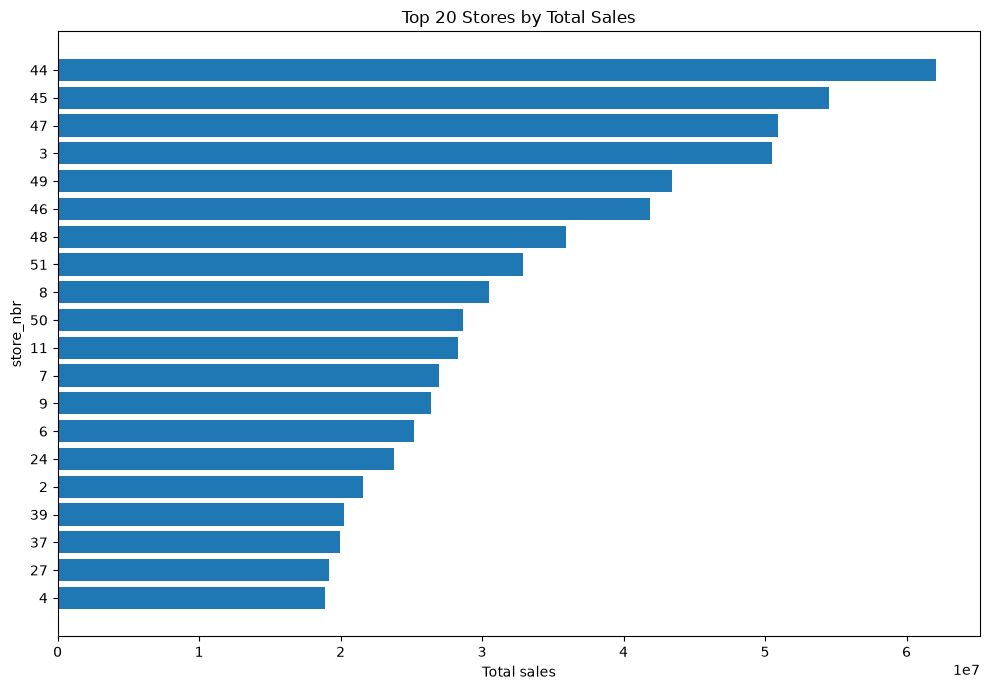

In [42]:
top_store = store_sales_df.head(20).sort_values("unit_sales")

plt.figure(figsize=(10, 7))
plt.barh(top_store.index.astype(str), top_store["unit_sales"])
plt.xlabel("Total sales")
plt.ylabel("store_nbr")
plt.title("Top 20 Stores by Total Sales")
plt.tight_layout()
plt.show()

Cửa hàng 44 chiếm khoảng 5,8% tổng doanh số; 10 cửa hàng lớn nhất chiếm khoảng 40,2%. Quy mô cửa hàng khác nhau rõ, nên cần xem thêm loại, cụm và vị trí cửa hàng.


## 27. Doanh số theo mặt hàng

Thống kê mức bán và mức tập trung giữa các mặt hàng.


In [43]:
item_sales = {}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["item_nbr", "unit_sales"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("item_nbr")["unit_sales"].sum()

    for item, value in grouped.items():
        item_sales[item] = item_sales.get(item, 0.0) + float(value)

item_sales_df = (
    pd.Series(item_sales, name="unit_sales")
    .sort_values(ascending=False)
    .to_frame()
)

item_sales_df.head(20)

,unit_sales
1503844,6.264200e+06
1047679,5.512875e+06
1473474,4.990323e+06
364606,4.416426e+06
819932,4.410943e+06
1463992,4.408545e+06
807493,4.321424e+06
265559,4.112827e+06
502331,3.703350e+06
314384,3.544341e+06


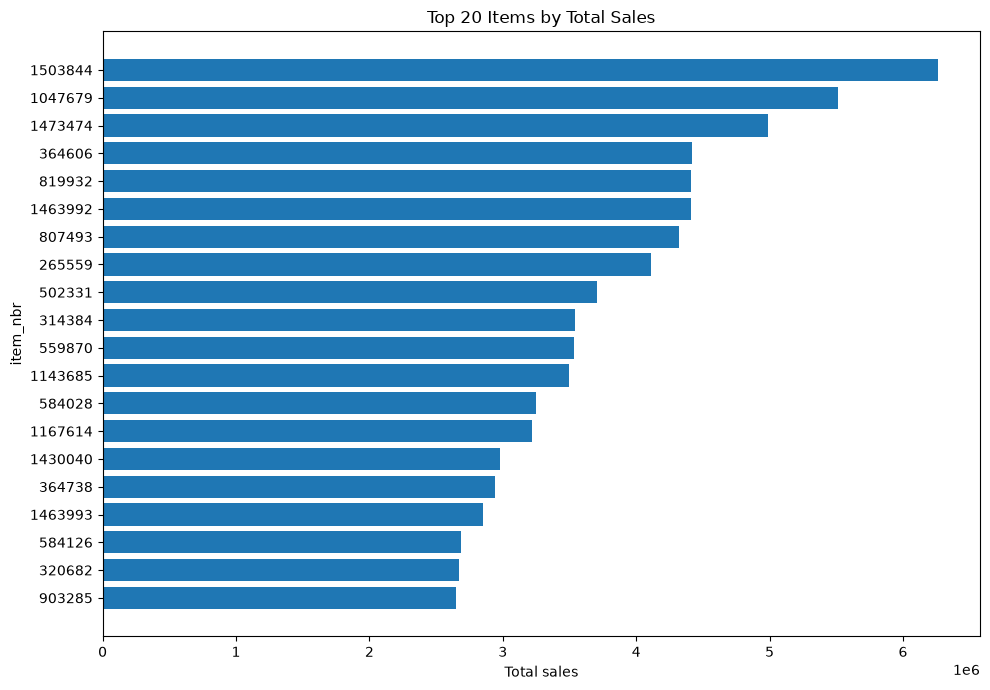

In [44]:
top_items = item_sales_df.head(20).sort_values("unit_sales")

plt.figure(figsize=(10, 7))
plt.barh(top_items.index.astype(str), top_items["unit_sales"])
plt.xlabel("Total sales")
plt.ylabel("item_nbr")
plt.title("Top 20 Items by Total Sales")
plt.tight_layout()
plt.show()

Doanh số phân bố lệch giữa các mặt hàng. Gini của mặt hàng là 0,585, cao hơn mức 0,341 của cửa hàng.

Không so sánh trực tiếp “top 20 mặt hàng” với “top 20 cửa hàng” để kết luận mức tập trung, vì tổng số đối tượng khác nhau.


## 28. Doanh số và khuyến mãi

So sánh các dòng đã biết trạng thái khuyến mãi.


In [45]:
promotion_stats = {
    True: {"rows": 0, "unit_sales": 0.0},
    False: {"rows": 0, "unit_sales": 0.0},
}

for chunk in pd.read_csv(
    RAW_DATA_DIR / "train.csv",
    usecols=["unit_sales", "onpromotion"],
    chunksize=DEFAULT_CHUNK_SIZE,
):
    grouped = chunk.groupby("onpromotion")["unit_sales"].agg(["count", "sum"])

    for promo_value, row in grouped.iterrows():
        if pd.isna(promo_value):
            continue

        key = bool(promo_value)
        promotion_stats[key]["rows"] += int(row["count"])
        promotion_stats[key]["unit_sales"] += float(row["sum"])

promotion_df = pd.DataFrame(promotion_stats).T
promotion_df["mean_sales"] = promotion_df["unit_sales"] / promotion_df["rows"]
promotion_df

,rows,unit_sales,mean_sales
True,7810622.0,1.051830e+08,13.466666
False,96028767.0,7.766937e+08,8.088135


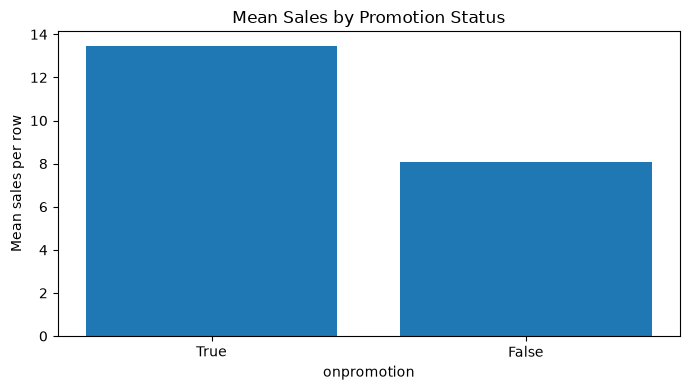

In [46]:
plt.figure(figsize=(7, 4))
plt.bar(
    promotion_df.index.astype(str),
    promotion_df["mean_sales"]
)
plt.xlabel("onpromotion")
plt.ylabel("Mean sales per row")
plt.title("Mean Sales by Promotion Status")
plt.tight_layout()
plt.show()

Doanh số trung bình của dòng có khuyến mãi là 13,47, so với 8,09 khi không khuyến mãi; tỷ lệ khoảng 1,66.

Đây là so sánh gộp, còn chịu ảnh hưởng của mặt hàng, cửa hàng và thời điểm. Không coi tỷ lệ này là tác động nhân quả của khuyến mãi.


## 29. Giá dầu

Xem phạm vi ngày, giá trị thiếu và xu hướng giá dầu.


Oil columns: ['dcoilwtico']


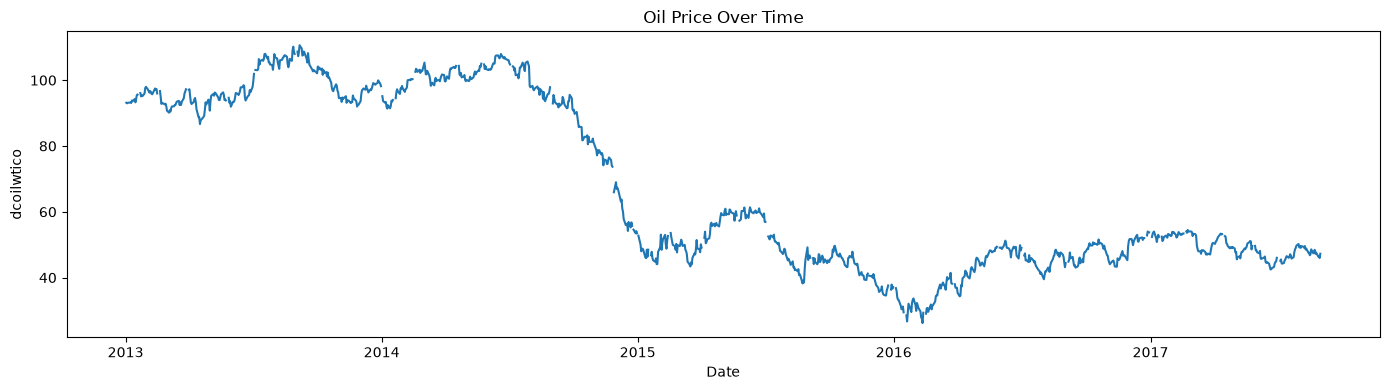

In [47]:
if "oil.csv" in small_tables:
    oil_df = small_tables["oil.csv"].copy()
    oil_df["date"] = pd.to_datetime(oil_df["date"], errors="coerce")

    oil_columns = [c for c in oil_df.columns if c != "date"]
    print("Oil columns:", oil_columns)

    if oil_columns:
        oil_col = oil_columns[0]

        plt.figure(figsize=(14, 4))
        plt.plot(oil_df["date"], oil_df[oil_col])
        plt.xlabel("Date")
        plt.ylabel(oil_col)
        plt.title("Oil Price Over Time")
        plt.tight_layout()
        plt.show()
else:
    print("oil.csv not available.")

Bảng dầu có 1.218 dòng, thiếu 43 giá trị. Khi tạo feature, chỉ dùng giá đã biết tại ngày cắt; không lấy giá tương lai để điền ngược.


## 30. Ngày lễ và sự kiện

Thống kê loại ngày, phạm vi áp dụng và ngày lễ bị dời.


In [48]:
if "holidays_events.csv" in small_tables:
    holidays_df = small_tables["holidays_events.csv"].copy()
    holidays_df["date"] = pd.to_datetime(holidays_df["date"], errors="coerce")

    print("Rows:", len(holidays_df))
    display(holidays_df.head())

    for col in ["type", "locale", "locale_name", "transferred"]:
        if col in holidays_df.columns:
            print(f"\nValue counts: {col}")
            display(holidays_df[col].value_counts(dropna=False).head(20))
else:
    print("holidays_events.csv not available.")

Rows: 350


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False



Value counts: type


type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


Value counts: locale


locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


Value counts: locale_name


locale_name
Ecuador          174
Quito             13
Riobamba          12
Guaranda          12
Latacunga         12
Ambato            12
Guayaquil         11
Cuenca             7
Ibarra             7
Manta              6
Cotopaxi           6
Libertad           6
Puyo               6
Imbabura           6
Machala            6
Santo Domingo      6
El Carmen          6
Cayambe            6
Esmeraldas         6
Quevedo            6
Name: count, dtype: int64


Value counts: transferred


transferred
False    338
True      12
Name: count, dtype: int64

Có 350 dòng ngày lễ/sự kiện. `National` áp dụng toàn quốc; `Regional` theo tỉnh; `Local` theo thành phố. Có 12 dòng lễ gốc bị dời; ngày nghỉ thực tế nằm ở dòng `Transfer`.


## 31. Tương quan giữa các biến

So sánh tổng doanh số với giao dịch, giá dầu và khuyến mãi.


In [49]:
if "oil.csv" in small_tables:
    oil_df = small_tables["oil.csv"].copy()
    oil_df["date"] = pd.to_datetime(oil_df["date"], errors="coerce")

    oil_columns = [c for c in oil_df.columns if c != "date"]

    if oil_columns:
        oil_col = oil_columns[0]

        cross_df = daily_sales_df.reset_index().rename(columns={"index": "date"})
        cross_df = cross_df.merge(
            oil_df[["date", oil_col]],
            on="date",
            how="left"
        )

        display(cross_df[["date", "unit_sales", oil_col]].head())

        print("Correlation on available paired dates:")
        display(cross_df[["unit_sales", oil_col]].corr())
else:
    print("Skipping sales × oil analysis because oil.csv is unavailable.")

,date,unit_sales,dcoilwtico
0,2013-01-01,2511.619,NaN
1,2013-01-02,496092.418,93.14
2,2013-01-03,361429.231,92.97
3,2013-01-04,354459.677,93.12
4,2013-01-05,477350.121,NaN


Correlation on available paired dates:


,unit_sales,dcoilwtico
unit_sales,1.000000,-0.705029
dcoilwtico,-0.705029,1.000000


Tương quan dầu −0,705 ở cách tính này có thể bị chi phối bởi xu hướng thời gian. Nó chưa chứng minh dầu tác động đến doanh số hay có ích cho dự báo. Phần sau tính lại tương quan sau chênh lệch 7 ngày.


## 32. Độ thưa và độ phủ dữ liệu

Đếm số ngày có dòng của từng cặp và theo dõi số dòng ghi nhận theo thời gian.


,value
stores_seen,54.000000
items_seen,4036.000000
pairs_seen,174685.000000
pairs_seen_vs_grid_pct,80.151323
mean_rows_per_day,74523.182898
mean_rows_per_day_vs_grid_pct,34.193730
overall_fill_rate_in_active_window,0.663693
implied_missing_day_share_in_window,0.336307
pairs_with_fill_rate_lt_50pct,29.425537
pairs_with_fill_rate_lt_20pct,9.436987


,rows,window_days,fill_rate
family,,,
SCHOOL AND OFFICE SUPPLIES,64327,373387,0.172
HOME AND KITCHEN I,561285,3077002,0.182
BABY CARE,5337,27711,0.193
HARDWARE,69535,307272,0.226
LINGERIE,291782,1259185,0.232
HOME AND KITCHEN II,483970,1786897,0.271
AUTOMOTIVE,320178,1165733,0.275
LADIESWEAR,276241,973018,0.284
HOME APPLIANCES,24120,81266,0.297


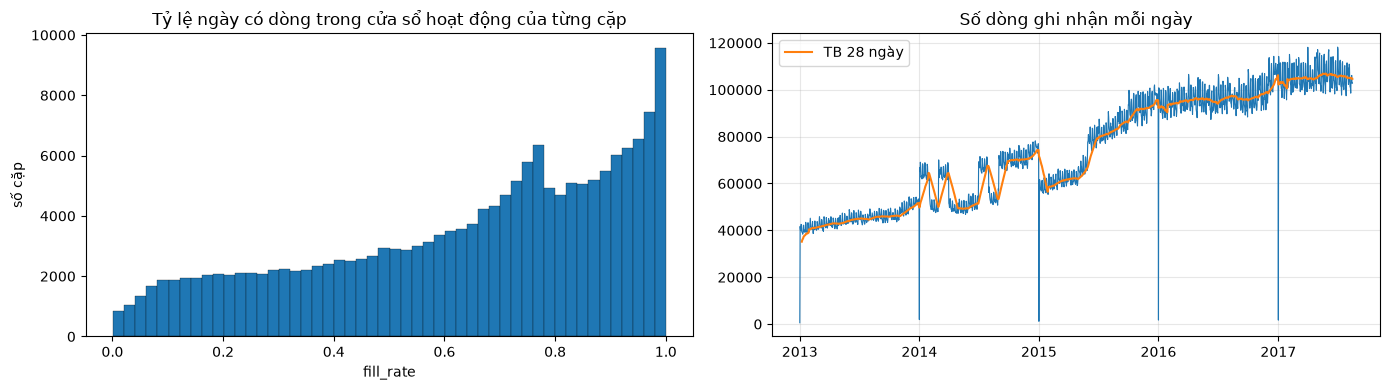

In [50]:
import matplotlib.pyplot as plt

pair = eda["pair"].copy()
daily = eda["daily"].copy()
train_start, train_end = daily["date"].min(), daily["date"].max()

n_stores_ever = pair["store_nbr"].nunique()
n_items_ever = pair["item_nbr"].nunique()
grid_pairs = n_stores_ever * n_items_ever

pair["window_days"] = (pair["last_date"] - pair["first_date"]).dt.days + 1
pair["fill_rate"] = pair["rows"] / pair["window_days"]
active_recent = pair["last_date"] >= train_end - pd.Timedelta(days=27)

sparsity = pd.Series({
    "stores_seen": n_stores_ever,
    "items_seen": n_items_ever,
    "pairs_seen": len(pair),
    "pairs_seen_vs_grid_pct": len(pair) / grid_pairs * 100,
    "mean_rows_per_day": daily["rows"].mean(),
    "mean_rows_per_day_vs_grid_pct": daily["rows"].mean() / grid_pairs * 100,
    "overall_fill_rate_in_active_window": pair["rows"].sum() / pair["window_days"].sum(),
    "implied_missing_day_share_in_window": 1 - pair["rows"].sum() / pair["window_days"].sum(),
    "pairs_with_fill_rate_lt_50pct": float((pair["fill_rate"] < 0.5).mean() * 100),
    "pairs_with_fill_rate_lt_20pct": float((pair["fill_rate"] < 0.2).mean() * 100),
    "pairs_active_in_last_28_days_pct": float(active_recent.mean() * 100),
})
display(sparsity.to_frame("value"))

items_meta = small_tables["items.csv"][["item_nbr", "family", "perishable"]].copy()
items_meta["item_nbr"] = items_meta["item_nbr"].astype(int)
fill_by_family = (
    pair.merge(items_meta, on="item_nbr", how="left")
    .groupby("family", dropna=False)[["rows", "window_days"]].sum()
)
fill_by_family["fill_rate"] = fill_by_family["rows"] / fill_by_family["window_days"]
display(fill_by_family.sort_values("fill_rate").round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(pair["fill_rate"], bins=50, edgecolor="black", linewidth=0.2)
axes[0].set_title("Tỷ lệ ngày có dòng trong cửa sổ hoạt động của từng cặp")
axes[0].set_xlabel("fill_rate"); axes[0].set_ylabel("số cặp")
axes[1].plot(daily["date"], daily["rows"], linewidth=0.8)
axes[1].plot(daily["date"], daily["rows"].rolling(28, min_periods=7).mean(), linewidth=1.5, label="TB 28 ngày")
axes[1].set_title("Số dòng ghi nhận mỗi ngày"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Tương quan tổng doanh số vs số dòng — theo tháng (tháng đủ ngày): 0.965 | theo ngày: 0.856
Doanh số mỗi dòng: min 7.52, max 10.93


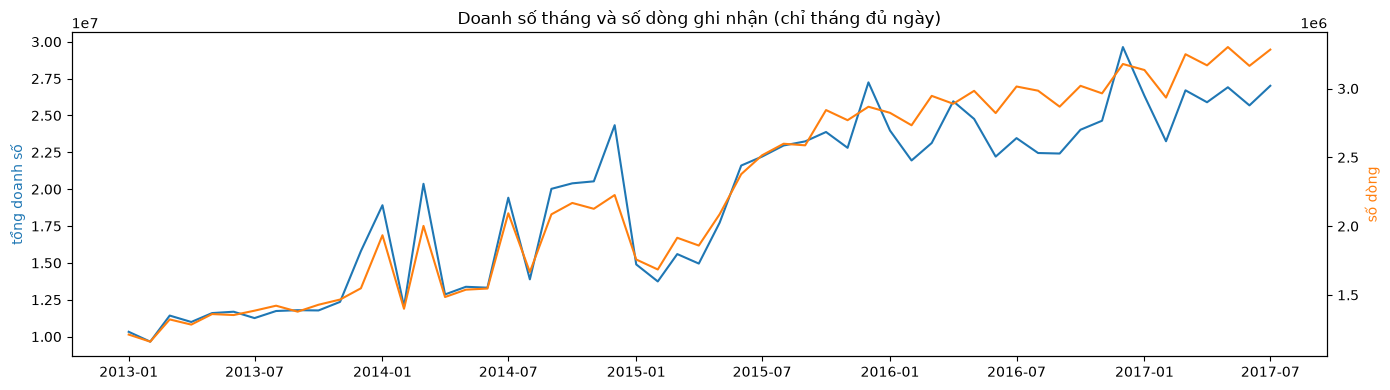

In [51]:
monthly = daily.set_index("date")[["rows", "sales"]].resample("MS").sum()
monthly["days_observed"] = daily.set_index("date")["rows"].resample("MS").count()
monthly["sales_per_row"] = monthly["sales"] / monthly["rows"]
complete_months = monthly[monthly["days_observed"] >= 27]     # bỏ tháng chưa đủ (ví dụ 2017-08)

corr_monthly = complete_months["rows"].corr(complete_months["sales"])
corr_daily = daily["rows"].corr(daily["sales"])
print(f"Tương quan tổng doanh số vs số dòng — theo tháng (tháng đủ ngày): {corr_monthly:.3f} | theo ngày: {corr_daily:.3f}")
print(f"Doanh số mỗi dòng: min {complete_months['sales_per_row'].min():.2f}, max {complete_months['sales_per_row'].max():.2f}")

fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(complete_months.index, complete_months["sales"], color="tab:blue", label="tổng doanh số")
ax1.set_ylabel("tổng doanh số", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(complete_months.index, complete_months["rows"], color="tab:orange", label="số dòng ghi nhận")
ax2.set_ylabel("số dòng", color="tab:orange")
ax1.set_title("Doanh số tháng và số dòng ghi nhận (chỉ tháng đủ ngày)")
plt.tight_layout(); plt.show()

Train phủ khoảng **34,2%** lưới cặp–ngày. Trong khoảng từ lần đầu đến lần cuối xuất hiện của cặp, **66,4%** ngày có dòng; phần còn lại có thể là không bán hoặc không niêm yết.

Tương quan giữa doanh số tháng và số dòng là **0,965**. Cần đọc biến động doanh số cùng độ phủ dữ liệu. Dựng toàn bộ lưới lịch sử sẽ rất lớn, nên feature được xử lý theo cửa sổ và từng mốc.


## 33. Khuyến mãi trong cùng cặp

So sánh doanh số có/không có khuyến mãi trong cùng cặp cửa hàng–mặt hàng, rồi đối chiếu tỷ lệ khuyến mãi với test.


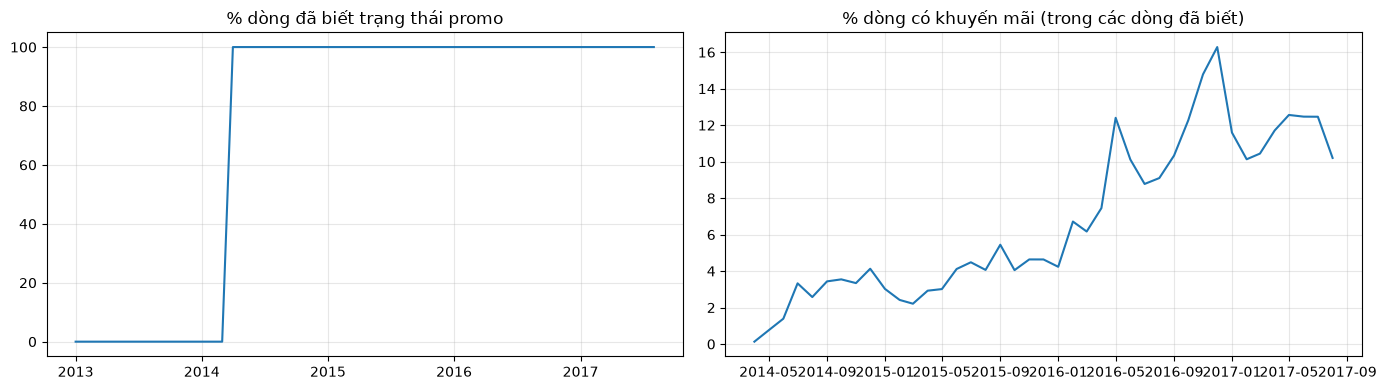

,value
pooled_mean_with_promo,13.466666
pooled_mean_without_promo,8.088135
pooled_ratio,1.664990
pairs_with_both_states,119638.000000
within_pair_ratio_median,1.291789
within_pair_ratio_p25,1.045644
within_pair_ratio_p75,1.698717
share_pairs_ratio_gt_1_pct,79.589261
geometric_mean_ratio,1.388534


,count,median
family,,
SCHOOL AND OFFICE SUPPLIES,376,1.532
BEVERAGES,18727,1.446
GROCERY I,37240,1.397
PRODUCE,10835,1.336
PERSONAL CARE,4804,1.310
HOME CARE,3534,1.305
"LIQUOR,WINE,BEER",1327,1.285
CLEANING,12687,1.282
BREAD/BAKERY,3966,1.269


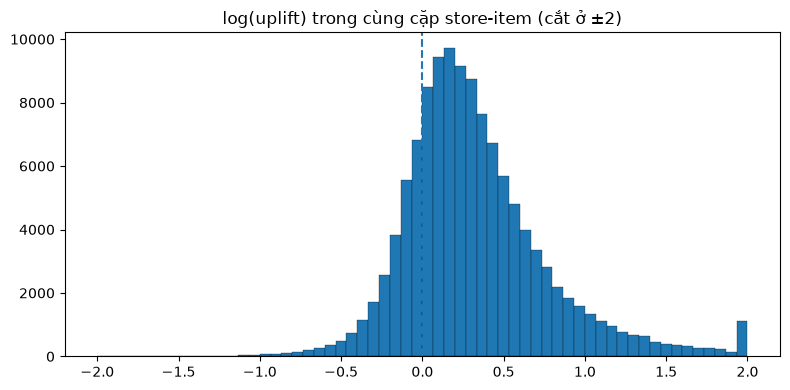

In [52]:
daily = eda["daily"].copy()
monthly_promo = daily.set_index("date")[["rows", "promo_true_rows", "promo_false_rows", "promo_missing_rows"]].resample("MS").sum()
known = monthly_promo["promo_true_rows"] + monthly_promo["promo_false_rows"]
monthly_promo["known_share_pct"] = known / monthly_promo["rows"] * 100
monthly_promo["promo_rate_known_pct"] = monthly_promo["promo_true_rows"] / known.replace(0, np.nan) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(monthly_promo.index, monthly_promo["known_share_pct"]); axes[0].set_title("% dòng đã biết trạng thái promo")
axes[1].plot(monthly_promo.index, monthly_promo["promo_rate_known_pct"]); axes[1].set_title("% dòng có khuyến mãi (trong các dòng đã biết)")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

pair = eda["pair"].copy()
MIN_ROWS_PER_STATE = 5
both = pair[(pair["promo_true_rows"] >= MIN_ROWS_PER_STATE) & (pair["promo_false_rows"] >= MIN_ROWS_PER_STATE)].copy()
both["mean_promo"] = both["sales_promo_true"] / both["promo_true_rows"]
both["mean_no_promo"] = both["sales_promo_false"] / both["promo_false_rows"]
both = both[both["mean_no_promo"] > 0].copy()
both["uplift_ratio"] = both["mean_promo"] / both["mean_no_promo"]
both["log_uplift"] = np.log(both["uplift_ratio"].clip(lower=1e-6))

pooled_promo = pair["sales_promo_true"].sum() / pair["promo_true_rows"].sum()
pooled_no = pair["sales_promo_false"].sum() / pair["promo_false_rows"].sum()

summary = pd.Series({
    "pooled_mean_with_promo": pooled_promo,
    "pooled_mean_without_promo": pooled_no,
    "pooled_ratio": pooled_promo / pooled_no,
    "pairs_with_both_states": len(both),
    "within_pair_ratio_median": both["uplift_ratio"].median(),
    "within_pair_ratio_p25": both["uplift_ratio"].quantile(0.25),
    "within_pair_ratio_p75": both["uplift_ratio"].quantile(0.75),
    "share_pairs_ratio_gt_1_pct": float((both["uplift_ratio"] > 1).mean() * 100),
    "geometric_mean_ratio": float(np.exp(both["log_uplift"].mean())),
})
display(summary.to_frame("value"))

items_meta = small_tables["items.csv"][["item_nbr", "family", "perishable"]].copy()
items_meta["item_nbr"] = items_meta["item_nbr"].astype(int)
uplift_family = (both.merge(items_meta, on="item_nbr", how="left")
                 .groupby("family")["uplift_ratio"].agg(["count", "median"]).sort_values("median", ascending=False))
display(uplift_family.head(15).round(3))

plt.figure(figsize=(8, 4))
plt.hist(both["log_uplift"].clip(-2, 2), bins=60, edgecolor="black", linewidth=0.2)
plt.axvline(0, linestyle="--"); plt.title("log(uplift) trong cùng cặp store-item (cắt ở ±2)")
plt.tight_layout(); plt.show()

In [53]:
test_promo = pd.read_csv(RAW_DATA_DIR / "test.csv", usecols=["date", "onpromotion"], dtype={"date": "string", "onpromotion": "string"})
test_flag = test_promo["onpromotion"].str.strip().str.lower().isin(["true", "1"])
test_rate_pct = float(test_flag.mean() * 100)

recent = daily[daily["date"] > daily["date"].max() - pd.Timedelta(days=28)]
recent_known = recent["promo_true_rows"].sum() + recent["promo_false_rows"].sum()
recent_rate_pct = float(recent["promo_true_rows"].sum() / recent_known * 100) if recent_known else float("nan")

print(f"Tỷ lệ onpromotion = True trong test          : {test_rate_pct:.2f}%")
print(f"Tỷ lệ onpromotion = True, 28 ngày cuối train : {recent_rate_pct:.2f}%")
display(test_flag.groupby(test_promo["date"]).mean().mul(100).round(2).rename("promo_pct").to_frame())
del test_promo, test_flag

Tỷ lệ onpromotion = True trong test          : 5.89%
Tỷ lệ onpromotion = True, 28 ngày cuối train : 10.74%


,promo_pct
date,
2017-08-16,14.50
2017-08-17,3.56
2017-08-18,6.54
2017-08-19,4.09
2017-08-20,4.52
2017-08-21,3.85
2017-08-22,4.89
2017-08-23,7.83
2017-08-24,3.92


Tỷ lệ doanh số có/không khuyến mãi trong cùng cặp có trung vị **1,29**, thấp hơn tỷ lệ gộp 1,66. Khoảng 79,6% cặp có mức bán cao hơn khi có khuyến mãi; thời điểm và ngày lễ vẫn có thể gây nhiễu.

Tỷ lệ khuyến mãi ở train thưa và test đầy đủ dùng mẫu số khác nhau, nên không so sánh trực tiếp để kết luận lệch phân phối. Notebook 03 tính lại trên lưới cặp–ngày và kiểm tra rủi ro do chỉ quan sát khuyến mãi khi có dòng bán.


## 34. Nhóm hàng và hàng mau hỏng

Xem tỷ trọng doanh số, giá trị không nguyên và mức tập trung theo nhóm hàng.


,items,rows,sales,neg_rows,frac_rows,sales_share_pct,sales_per_row,negative_pct,fractional_pct
family,,,,,,,,,
GROCERY I,1290,45628065,3.434617e+08,2160,13785,31.991,7.527,0.005,0.030
BEVERAGES,604,17567388,2.169422e+08,1361,0,20.207,12.349,0.008,0.000
PRODUCE,306,7154303,1.227047e+08,302,3431233,11.429,17.151,0.004,47.960
CLEANING,446,17015600,9.751840e+07,1026,0,9.083,5.731,0.006,0.000
DAIRY,242,8992824,6.448726e+07,380,0,6.007,7.171,0.004,0.000
BREAD/BAKERY,134,4659246,4.213395e+07,194,39425,3.925,9.043,0.004,0.846
POULTRY,54,1742403,3.187600e+07,148,1736955,2.969,18.294,0.008,99.687
MEATS,84,2432048,3.108647e+07,133,2405953,2.896,12.782,0.005,98.927
PERSONAL CARE,153,4522666,2.458094e+07,401,0,2.290,5.435,0.009,0.000


,items,rows,sales,items_pct,sales_pct
perishable,,,,,
0,3050,93794504,7.308080e+08,75.57,68.07
1,986,31702536,3.428022e+08,24.43,31.93


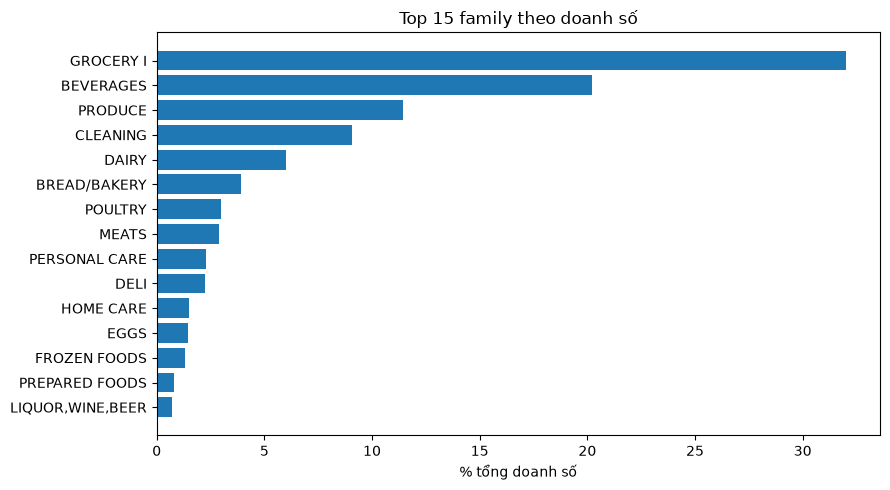

,gini,top_1pct_share,top_10pct_share,top_20pct_share
items,0.585,11.506,44.200,61.122
stores,0.341,5.783,28.253,42.813


In [54]:
pair = eda["pair"]
items_meta = small_tables["items.csv"][["item_nbr", "family", "class", "perishable"]].copy()
items_meta["item_nbr"] = items_meta["item_nbr"].astype(int)

item_totals = (pair.groupby("item_nbr", as_index=False)[["rows", "sales", "neg_rows", "frac_rows"]].sum()
               .merge(items_meta, on="item_nbr", how="left"))

family_table = item_totals.groupby("family", dropna=False).agg(
    items=("item_nbr", "nunique"), rows=("rows", "sum"), sales=("sales", "sum"),
    neg_rows=("neg_rows", "sum"), frac_rows=("frac_rows", "sum"))
family_table["sales_share_pct"] = family_table["sales"] / family_table["sales"].sum() * 100
family_table["sales_per_row"] = family_table["sales"] / family_table["rows"]
family_table["negative_pct"] = family_table["neg_rows"] / family_table["rows"] * 100
family_table["fractional_pct"] = family_table["frac_rows"] / family_table["rows"] * 100
family_table = family_table.sort_values("sales_share_pct", ascending=False)
display(family_table.round(3))

perishable_table = item_totals.groupby("perishable").agg(items=("item_nbr", "nunique"), rows=("rows", "sum"), sales=("sales", "sum"))
perishable_table["items_pct"] = perishable_table["items"] / perishable_table["items"].sum() * 100
perishable_table["sales_pct"] = perishable_table["sales"] / perishable_table["sales"].sum() * 100
display(perishable_table.round(2))

top15 = family_table.head(15).sort_values("sales_share_pct")
plt.figure(figsize=(9, 5)); plt.barh(top15.index.astype(str), top15["sales_share_pct"])
plt.xlabel("% tổng doanh số"); plt.title("Top 15 family theo doanh số"); plt.tight_layout(); plt.show()


def gini(values):
    x = np.sort(np.clip(np.asarray(values, dtype="float64"), 0, None))
    n = len(x)
    return float((2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n)


def top_share(values, fraction):
    x = np.sort(np.clip(np.asarray(values, dtype="float64"), 0, None))[::-1]
    k = max(int(np.ceil(fraction * len(x))), 1)
    return float(x[:k].sum() / x.sum() * 100)


store_totals = pair.groupby("store_nbr")["sales"].sum()
concentration = pd.DataFrame({
    "gini": [gini(item_totals["sales"]), gini(store_totals)],
    "top_1pct_share": [top_share(item_totals["sales"], 0.01), top_share(store_totals, 0.01)],
    "top_10pct_share": [top_share(item_totals["sales"], 0.10), top_share(store_totals, 0.10)],
    "top_20pct_share": [top_share(item_totals["sales"], 0.20), top_share(store_totals, 0.20)],
}, index=["items", "stores"])
display(concentration.round(3))

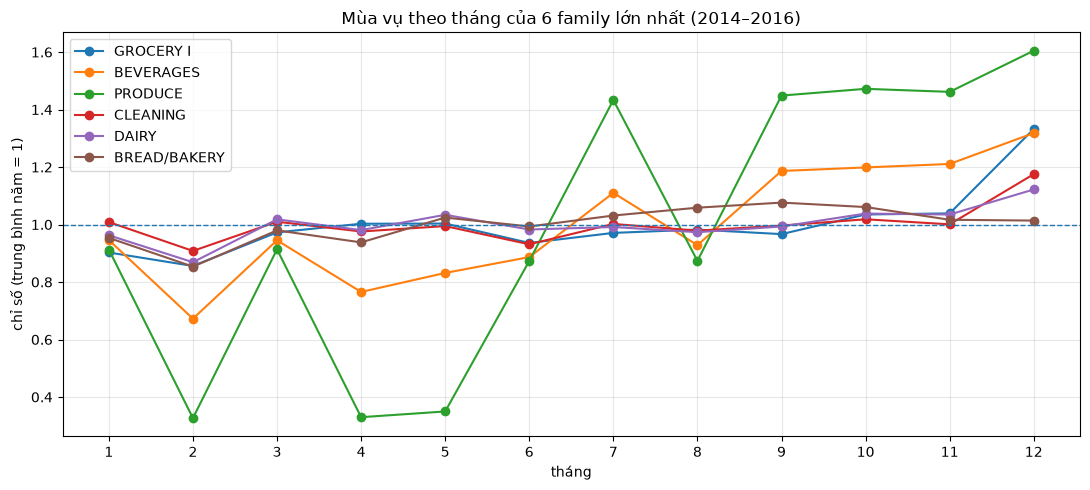

In [55]:
item_month = eda["item_month"].merge(items_meta[["item_nbr", "family"]], on="item_nbr", how="left")
item_month["year"] = item_month["ym"].str.slice(0, 4).astype(int)
item_month["month"] = item_month["ym"].str.slice(5, 7).astype(int)

full_years = item_month[item_month["year"].isin([2014, 2015, 2016])]
family_month = full_years.groupby(["family", "year", "month"])["sales"].sum().reset_index()
family_month["index"] = family_month["sales"] / family_month.groupby(["family", "year"])["sales"].transform("mean")
seasonal = family_month.groupby(["family", "month"])["index"].mean().unstack("month")

top_families = family_table.head(6).index.tolist()
plt.figure(figsize=(11, 5))
for fam in top_families:
    if fam in seasonal.index:
        plt.plot(seasonal.columns, seasonal.loc[fam], marker="o", label=str(fam))
plt.axhline(1, linestyle="--", linewidth=1)
plt.xticks(range(1, 13)); plt.xlabel("tháng"); plt.ylabel("chỉ số (trung bình năm = 1)")
plt.title("Mùa vụ theo tháng của 6 family lớn nhất (2014–2016)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Năm nhóm GROCERY I, BEVERAGES, PRODUCE, CLEANING và DAIRY chiếm khoảng **78,7%** doanh số. Hàng mau hỏng chiếm khoảng **31,9%** doanh số và được chấm trọng số 1,25.

Số thực tập trung ở các nhóm bán theo khối lượng như thịt và rau quả; không làm tròn target. Biểu đồ tổng doanh số theo tháng của mỗi nhóm còn chịu ảnh hưởng của số cặp được ghi nhận, chưa phản ánh riêng mùa vụ nhu cầu.


## 35. Lịch sử cửa hàng và giao dịch

Xem ngày bắt đầu có dữ liệu, metadata cửa hàng và độ phủ bảng giao dịch.


Cửa hàng mở muộn (> 30 ngày sau ngày đầu của train): 8


,store_nbr,city,type,first_date,active_days,coverage
35,36,Libertad,E,2013-05-09,1553,0.995513
52,53,Manta,D,2014-05-29,1169,0.994894
19,20,Quito,B,2015-02-13,911,0.995628
28,29,Guayaquil,E,2015-03-20,876,0.995455
20,21,Santo Domingo,B,2015-07-24,750,0.994695
41,42,Cuenca,D,2015-08-21,722,0.994490
21,22,Puyo,C,2015-10-09,673,0.994092
51,52,Manta,A,2017-04-20,118,1.000000


Cửa hàng ngừng ghi nhận trước ngày cuối train > 7 ngày: 0


,store_nbr,city,type,last_date


,stores,sales,active_days,sales_per_store_day,sales_share_pct
type,,,,,
A,9,3.530438e+08,13550,26054.89,32.88
B,8,1.452483e+08,11625,12494.47,13.53
C,15,1.644345e+08,24056,6835.49,15.32
D,18,3.510633e+08,28592,12278.38,32.70
E,4,5.982042e+07,5783,10344.19,5.57


,stores,sales,active_days,sales_per_store_day
cluster,,,,
5,1,62087544.3,1679,36978.9
11,3,100614269.9,3476,28945.4
14,4,157430508.1,6716,23441.1
8,3,107925255.7,5037,21426.5
17,1,32911484.5,1679,19601.8
6,6,114254327.7,8377,13639.1
2,2,28915601.8,2401,12043.1
13,4,72088210.8,6205,11617.8
1,3,54376746.0,4875,11154.2


,stores,sales
state,,
Pichincha,19,5.850493e+08
Guayas,11,1.651522e+08
Azuay,3,4.916779e+07
Tungurahua,2,4.030440e+07
Santo Domingo de los Tsachilas,3,3.583432e+07
El Oro,2,3.338676e+07
Los Rios,2,3.192529e+07
Manabi,3,2.495856e+07
Cotopaxi,2,2.118222e+07


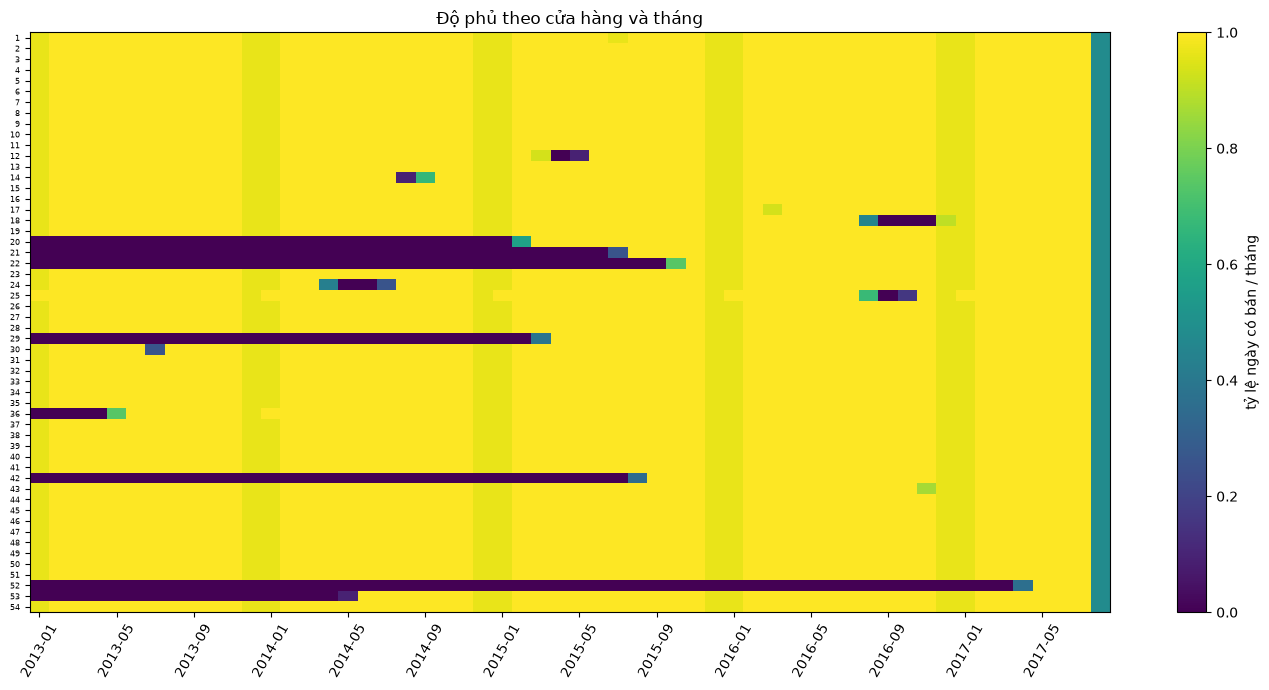

In [56]:
store_day = eda["store_day"].copy()
stores_meta = small_tables["stores.csv"].copy()
stores_meta["store_nbr"] = stores_meta["store_nbr"].astype(int)
train_start, train_end = store_day["date"].min(), store_day["date"].max()

life = store_day.groupby("store_nbr").agg(
    first_date=("date", "min"), last_date=("date", "max"), active_days=("date", "nunique"),
    sales=("sales", "sum"), rows=("rows", "sum")).reset_index()
life["span_days"] = (life["last_date"] - life["first_date"]).dt.days + 1
life["coverage"] = life["active_days"] / life["span_days"]
life["sales_per_active_day"] = life["sales"] / life["active_days"]
life = life.merge(stores_meta, on="store_nbr", how="left")

late_open = life[life["first_date"] > train_start + pd.Timedelta(days=30)].sort_values("first_date")
early_close = life[life["last_date"] < train_end - pd.Timedelta(days=7)]
print(f"Cửa hàng mở muộn (> 30 ngày sau ngày đầu của train): {len(late_open)}")
display(late_open[["store_nbr", "city", "type", "first_date", "active_days", "coverage"]])
print(f"Cửa hàng ngừng ghi nhận trước ngày cuối train > 7 ngày: {len(early_close)}")
display(early_close[["store_nbr", "city", "type", "last_date"]])

by_type = life.groupby("type").agg(stores=("store_nbr", "count"), sales=("sales", "sum"), active_days=("active_days", "sum"))
by_type["sales_per_store_day"] = by_type["sales"] / by_type["active_days"]
by_type["sales_share_pct"] = by_type["sales"] / by_type["sales"].sum() * 100
display(by_type.round(2))
by_cluster = life.groupby("cluster").agg(stores=("store_nbr", "count"), sales=("sales", "sum"), active_days=("active_days", "sum"))
by_cluster["sales_per_store_day"] = by_cluster["sales"] / by_cluster["active_days"]
display(by_cluster.sort_values("sales_per_store_day", ascending=False).round(1).head(10))
by_state = life.groupby("state").agg(stores=("store_nbr", "count"), sales=("sales", "sum")).sort_values("sales", ascending=False)
display(by_state.head(10))

sd = store_day.assign(ym=store_day["date"].dt.to_period("M"))
coverage = sd.groupby(["store_nbr", "ym"])["date"].nunique().unstack("ym").fillna(0)
days_in_month = pd.Series({p: p.days_in_month for p in coverage.columns})
coverage_share = coverage.div(days_in_month, axis=1).clip(upper=1)
plt.figure(figsize=(14, 7))
plt.imshow(coverage_share.values, aspect="auto", interpolation="nearest")
plt.colorbar(label="tỷ lệ ngày có bán / tháng")
plt.yticks(range(len(coverage_share.index)), coverage_share.index, fontsize=6)
step = max(len(coverage_share.columns) // 12, 1)
plt.xticks(range(0, len(coverage_share.columns), step), [str(c) for c in coverage_share.columns[::step]], rotation=60)
plt.title("Độ phủ theo cửa hàng và tháng"); plt.tight_layout(); plt.show()

,store-day
_merge,
cả hai bảng,83488
"có bán, thiếu transactions",118
"có transactions, không có bán",0


Tương quan toàn bộ store-day: 0.837 | tương quan trong từng cửa hàng (trung vị): 0.586
Doanh số mỗi giao dịch: trung vị 7.16


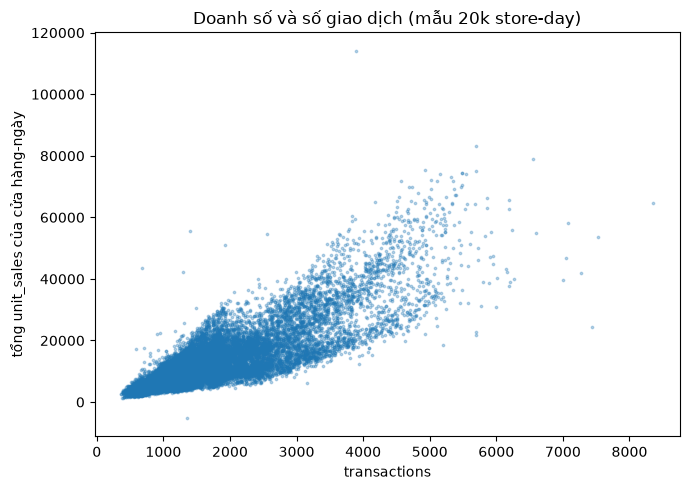

In [57]:
tx = small_tables["transactions.csv"].copy()
tx["date"] = pd.to_datetime(tx["date"])
tx["store_nbr"] = tx["store_nbr"].astype(int)

merged = store_day.merge(tx, on=["date", "store_nbr"], how="outer", indicator=True)
coverage_counts = merged["_merge"].value_counts().rename({"both": "cả hai bảng", "left_only": "có bán, thiếu transactions", "right_only": "có transactions, không có bán"})
display(coverage_counts.to_frame("store-day"))

joined = merged[merged["_merge"] == "both"].copy()
joined["sales_per_transaction"] = joined["sales"] / joined["transactions"]
overall_corr = joined["sales"].corr(joined["transactions"])
per_store_corr = pd.Series({s: g["sales"].corr(g["transactions"]) for s, g in joined.groupby("store_nbr")})
print(f"Tương quan toàn bộ store-day: {overall_corr:.3f} | tương quan trong từng cửa hàng (trung vị): {per_store_corr.median():.3f}")
print(f"Doanh số mỗi giao dịch: trung vị {joined['sales_per_transaction'].median():.2f}")

sample = joined.sample(min(20_000, len(joined)), random_state=42)
plt.figure(figsize=(7, 5)); plt.scatter(sample["transactions"], sample["sales"], s=3, alpha=0.3)
plt.xlabel("transactions"); plt.ylabel("tổng unit_sales của cửa hàng-ngày"); plt.title("Doanh số và số giao dịch (mẫu 20k store-day)")
plt.tight_layout(); plt.show()

Có **8 cửa hàng bắt đầu được ghi nhận muộn** hơn 30 ngày so với đầu train. Ngày đầu có dữ liệu là dấu mốc quan sát, chưa chắc là ngày mở cửa thực tế.

Cửa hàng loại A bán trung bình khoảng 2,1 lần loại B/D theo cửa hàng–ngày. Pichincha chiếm khoảng 54,5% doanh số.

Có 118 store-day bán hàng nhưng thiếu giao dịch. `transactions` kết thúc ngày 15/08/2017, nên chỉ dùng thống kê quá khứ khi dự báo.


## 36. Ngày lễ và hiệu ứng lịch

So sánh doanh số sau khi điều chỉnh thứ trong tuần. Xem riêng ngày đầu năm, cuối năm, đầu/cuối tháng và giai đoạn động đất.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_24188\3170362563.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow_factor = ratio[normal].groupby(idx[normal].dayofweek).median()
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_24188\3170362563.py:22: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  adjusted = ratio / pd.Series(idx.dayofweek, index=idx).map(dow_factor)


,nhóm,n_ngày,chỉ số TB,chỉ số trung vị
0,ngày thường,1531,1.017,1.000
1,lễ quốc gia (hiệu lực),77,1.138,1.144
2,sự kiện quốc gia (Event),55,1.021,0.995
3,Work Day,5,0.959,0.940
4,24–31/12,28,1.054,1.054
5,01/01,5,0.014,0.014


Lễ quốc gia làm doanh số THẤP hơn mức nền nhiều nhất:


,count,mean
description,,
Primer dia del ano,3,0.020
Primer Grito de Independencia,3,0.979
Viernes Santo,5,1.008
Batalla de Pichincha,3,1.036
Navidad+1,4,1.048
Puente Primer dia del ano,1,1.076


Lễ quốc gia làm doanh số CAO hơn mức nền nhiều nhất:


,count,mean
description,,
Navidad-1,4,1.275
Navidad-3,4,1.290
Independencia de Cuenca,4,1.419
Dia del Trabajo,5,1.463
Navidad-2,4,1.464
Traslado Primer dia del ano,1,1.493


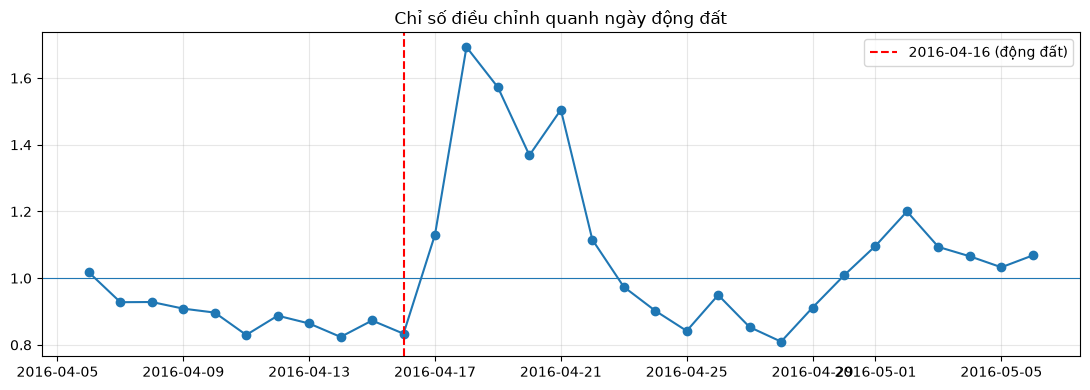

In [58]:
ts = eda["daily"].set_index("date")["sales"].asfreq("D")
is_jan1 = (ts.index.month == 1) & (ts.index.day == 1)
is_late_dec = (ts.index.month == 12) & (ts.index.day >= 24)

hol = small_tables["holidays_events"].copy() if "holidays_events" in small_tables else small_tables["holidays_events.csv"].copy()
hol["date"] = pd.to_datetime(hol["date"])
hol["transferred_flag"] = hol["transferred"].astype(str).str.strip().str.lower().eq("true")
national = hol[hol["locale"] == "National"]
nat_holiday = national[(national["type"].isin(["Holiday", "Additional", "Bridge"]) & ~national["transferred_flag"]) | (national["type"] == "Transfer")]
nat_event = national[national["type"] == "Event"]
nat_workday = national[national["type"] == "Work Day"]

idx = ts.index
in_holiday = idx.isin(nat_holiday["date"])
in_event = idx.isin(nat_event["date"])
in_workday = idx.isin(nat_workday["date"])

base = ts.where(~is_jan1).rolling(28, center=True, min_periods=14).mean()
ratio = ts / base
normal = ~(in_holiday | in_event | in_workday | is_jan1 | is_late_dec) & ratio.notna()
dow_factor = ratio[normal].groupby(idx[normal].dayofweek).median()
adjusted = ratio / pd.Series(idx.dayofweek, index=idx).map(dow_factor)

groups = {
    "ngày thường": normal,
    "lễ quốc gia (hiệu lực)": pd.Series(in_holiday, index=idx) & ratio.notna(),
    "sự kiện quốc gia (Event)": pd.Series(in_event, index=idx) & ratio.notna(),
    "Work Day": pd.Series(in_workday, index=idx) & ratio.notna(),
    "24–31/12": pd.Series(is_late_dec, index=idx) & ratio.notna(),
    "01/01": pd.Series(is_jan1, index=idx),
}
effect_rows = []
for name, mask in groups.items():
    values = adjusted[mask.to_numpy()].dropna() if name != "01/01" else (ts[is_jan1] / ts.rolling(28, center=True, min_periods=14).mean()[is_jan1]).dropna()
    effect_rows.append({"nhóm": name, "n_ngày": len(values), "chỉ số TB": values.mean(), "chỉ số trung vị": values.median()})
display(pd.DataFrame(effect_rows).round(3))

named = nat_holiday.assign(adj=nat_holiday["date"].map(adjusted)).dropna(subset=["adj"])
by_name = named.groupby("description")["adj"].agg(["count", "mean"]).sort_values("mean")
print("Lễ quốc gia làm doanh số THẤP hơn mức nền nhiều nhất:"); display(by_name.head(6).round(3))
print("Lễ quốc gia làm doanh số CAO hơn mức nền nhiều nhất:"); display(by_name.tail(6).round(3))

quake = hol[hol["description"].astype(str).str.contains("Terremoto", case=False)]
if len(quake):
    q0 = quake["date"].min()
    window = adjusted[(adjusted.index >= q0 - pd.Timedelta(days=10)) & (adjusted.index <= q0 + pd.Timedelta(days=20))]
    plt.figure(figsize=(11, 4)); plt.plot(window.index, window.values, marker="o")
    plt.axvline(q0, linestyle="--", color="red", label=f"{q0.date()} (động đất)"); plt.axhline(1, linewidth=0.8)
    plt.title("Chỉ số điều chỉnh quanh ngày động đất"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
else:
    print("Không tìm thấy sự kiện 'Terremoto' trong holidays_events.")

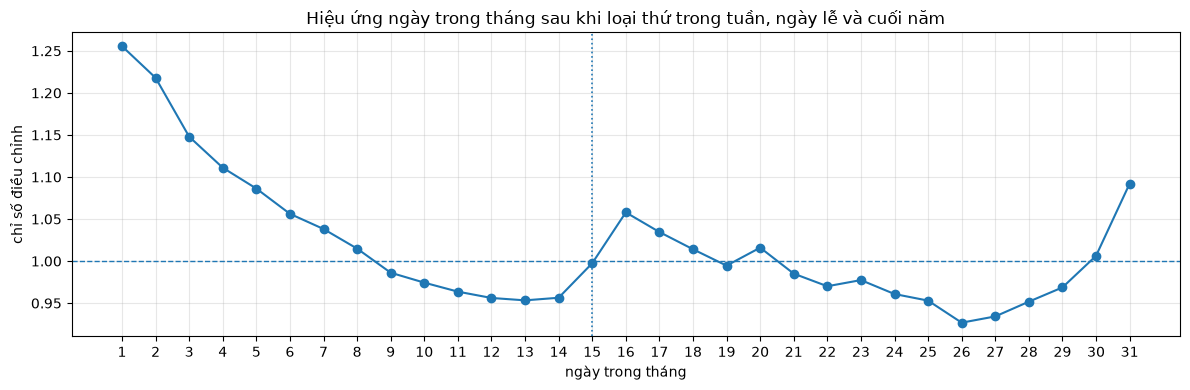

date,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
mean,1.256,1.218,1.148,1.111,1.086,1.056,1.038,1.015,0.986,0.974,...,0.97,0.977,0.961,0.953,0.927,0.934,0.952,0.969,1.006,1.092
count,44.000,49.000,49.000,52.000,53.000,55.000,55.000,53.000,50.000,48.000,...,50.00,50.000,47.000,47.000,49.000,47.000,46.000,44.000,43.000,28.000


In [59]:
mask_dom = normal & ratio.notna()
dom_profile = adjusted[mask_dom].groupby(adjusted[mask_dom].index.day).agg(["mean", "count"])
plt.figure(figsize=(12, 4))
plt.plot(dom_profile.index, dom_profile["mean"], marker="o")
plt.axhline(1, linestyle="--", linewidth=1); plt.axvline(15, linestyle=":", linewidth=1.2)
plt.xticks(range(1, 32)); plt.xlabel("ngày trong tháng"); plt.ylabel("chỉ số điều chỉnh")
plt.title("Hiệu ứng ngày trong tháng sau khi loại thứ trong tuần, ngày lễ và cuối năm"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()
display(dom_profile.round(3).T)

Chỉ số doanh số ngày 01/01 gần 0. Sau điều chỉnh, đầu tháng cao hơn; ngày 1 khoảng **1,256**, ngày 26 khoảng **0,927**, ngày 31 khoảng **1,092**.

Quanh 16/04/2016 có dao động mạnh, với chỉ số lên khoảng 1,7 rồi giảm. Kết quả cho thấy cần xét lịch và giai đoạn đặc biệt, nhưng chưa chứng minh riêng nguyên nhân của từng biến động.


## 37. Thang log và giá trị cực trị

So sánh phân phối trước/sau log1p. Xem các dòng âm, số thực và các giá trị lớn nhất.


,skew,kurtosis,mean,median
unit_sales (mẫu),19.765,1031.948,8.549,4.000
"log1p(clip(unit_sales, 0))",0.853,0.617,1.752,1.609


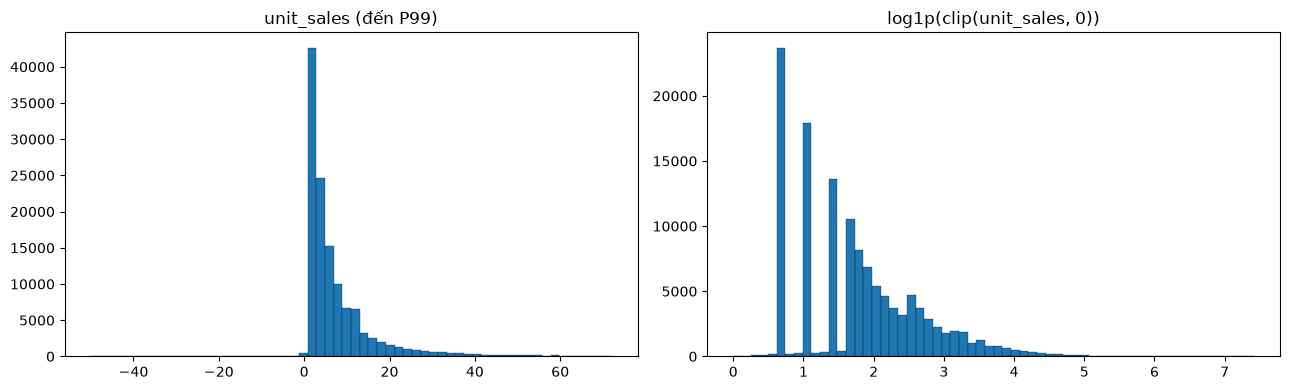

,neg_rows,rows,negative_pct
year,,,
2013,947,16322662,0.0058
2014,1350,22271602,0.0061
2015,1619,27864644,0.0058
2016,2246,35229871,0.0064
2017,1633,23808261,0.0069


20 giá trị lớn nhất:


,date,store_nbr,item_nbr,unit_sales,side,family,perishable,pair_mean,rows,ratio_to_pair_mean
0,2016-10-07,39,1976284,89440.00,largest,MEATS,1,6743.81,25,13.3
1,2016-04-21,20,841842,44142.00,largest,GROCERY I,0,99.08,907,445.5
2,2016-05-02,2,1162932,30000.00,largest,GROCERY I,0,212.85,214,140.9
3,2016-04-18,45,559870,20748.00,largest,GROCERY I,0,111.93,1679,185.4
4,2016-05-02,2,305227,20000.00,largest,GROCERY I,0,25.85,1504,773.8
5,2017-04-12,32,1963892,17146.00,largest,GROCERY I,0,238.53,203,71.9
6,2016-04-21,20,1464133,16000.00,largest,BEVERAGES,0,49.37,657,324.1
7,2017-06-25,54,2013931,15375.00,largest,BEVERAGES,0,1389.93,71,11.1
8,2016-04-26,2,1162932,15000.00,largest,GROCERY I,0,212.85,214,70.5
9,2017-04-02,9,754103,14483.00,largest,GROCERY I,0,22.81,1631,634.9


Họ hàng của 200 giá trị lớn nhất:


,số giá trị
family,
GROCERY I,97
BEVERAGES,37
MEATS,17
FROZEN FOODS,17
CLEANING,16
POULTRY,12
"LIQUOR,WINE,BEER",2
PRODUCE,1


Trong 200 giá trị lớn nhất, 88% cao hơn 10 lần mức trung bình của chính cặp đó (đột biến); phần còn lại thuộc cặp bán nhiều thường xuyên.
5 giá trị âm sâu nhất:


,date,store_nbr,item_nbr,unit_sales,family,perishable
200,2015-06-22,18,1166474,-15372.0,BEVERAGES,0
201,2017-04-06,32,1158720,-10002.0,GROCERY I,0
202,2016-05-14,53,119026,-4673.0,CLEANING,0
203,2016-05-14,53,323921,-3606.0,PERSONAL CARE,0
204,2016-05-14,53,1229028,-3600.0,PERSONAL CARE,0


In [60]:
y = pd.Series(target_sample).dropna().to_numpy(dtype="float64")
y_log = np.log1p(np.clip(y, 0, None))

shape_table = pd.DataFrame({
    "skew": [pd.Series(y).skew(), pd.Series(y_log).skew()],
    "kurtosis": [pd.Series(y).kurt(), pd.Series(y_log).kurt()],
    "mean": [y.mean(), y_log.mean()],
    "median": [np.median(y), np.median(y_log)],
}, index=["unit_sales (mẫu)", "log1p(clip(unit_sales, 0))"])
display(shape_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y[y <= np.quantile(y, 0.99)], bins=60, edgecolor="black", linewidth=0.2); axes[0].set_title("unit_sales (đến P99)")
axes[1].hist(y_log, bins=60, edgecolor="black", linewidth=0.2); axes[1].set_title("log1p(clip(unit_sales, 0))")
plt.tight_layout(); plt.show()

daily = eda["daily"]
neg_by_year = daily.assign(year=daily["date"].dt.year).groupby("year")[["neg_rows", "rows"]].sum()
neg_by_year["negative_pct"] = neg_by_year["neg_rows"] / neg_by_year["rows"] * 100
display(neg_by_year.round(4))

pair = eda["pair"].copy()
items_meta = small_tables["items.csv"][["item_nbr", "family", "perishable"]].copy()
items_meta["item_nbr"] = items_meta["item_nbr"].astype(int)
pair["pair_mean"] = pair["sales"] / pair["rows"]

extremes = eda["extremes"].merge(items_meta, on="item_nbr", how="left").merge(
    pair[["store_nbr", "item_nbr", "pair_mean", "rows"]], on=["store_nbr", "item_nbr"], how="left")
extremes["ratio_to_pair_mean"] = extremes["unit_sales"] / extremes["pair_mean"]
largest = extremes[extremes["side"] == "largest"].sort_values("unit_sales", ascending=False)
print("20 giá trị lớn nhất:"); display(largest.head(20).round({"unit_sales": 2, "pair_mean": 2, "ratio_to_pair_mean": 1}))
print("Họ hàng của 200 giá trị lớn nhất:"); display(largest["family"].value_counts().head(8).to_frame("số giá trị"))
spike_share = float((largest["ratio_to_pair_mean"] > 10).mean() * 100)
print(f"Trong 200 giá trị lớn nhất, {spike_share:.0f}% cao hơn 10 lần mức trung bình của chính cặp đó (đột biến); phần còn lại thuộc cặp bán nhiều thường xuyên.")
print("5 giá trị âm sâu nhất:"); display(extremes[extremes["side"] == "smallest"].sort_values("unit_sales").head(5)[["date", "store_nbr", "item_nbr", "unit_sales", "family", "perishable"]])

Trên mẫu đã dùng, `log1p(clip(y, 0))` giảm độ lệch từ **19,77 xuống 0,85**. Trong 200 giá trị lớn nhất, 88% cao hơn 10 lần trung bình của chính cặp.

Giữ các dòng này ở cleaning. Hiện target học chỉ cắt giá trị âm về 0 rồi lấy log; việc cắt thêm cực trị cần được thử bằng validation, không mặc định là cần thiết.


## 38. Chu kỳ tuần và tự tương quan

Kiểm tra các độ trễ và mức bán theo thứ trong tuần.


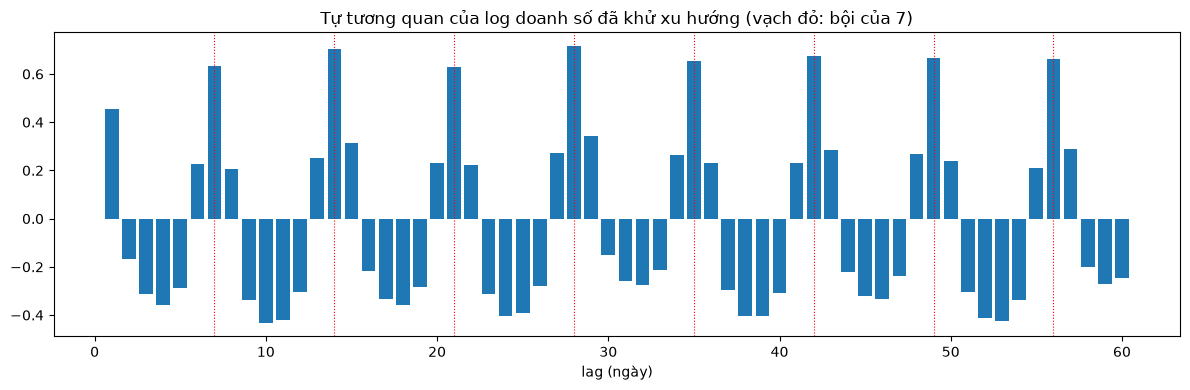

Lag có tự tương quan lớn nhất: {28: 0.715, 14: 0.703, 42: 0.676, 49: 0.668, 56: 0.662, 35: 0.653}


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_24188\3820531304.py:17: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  wk["year"] = wk.index.year; wk["dow"] = wk.index.dayofweek


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
year,,,,,,,
2013,0.973,0.875,0.886,0.800,0.899,1.251,1.316
2014,0.973,0.899,0.936,0.791,0.881,1.214,1.306
2015,0.955,0.897,0.935,0.807,0.900,1.203,1.303
2016,0.963,0.897,0.937,0.790,0.931,1.186,1.296
2017,0.964,0.897,0.943,0.782,0.934,1.206,1.274


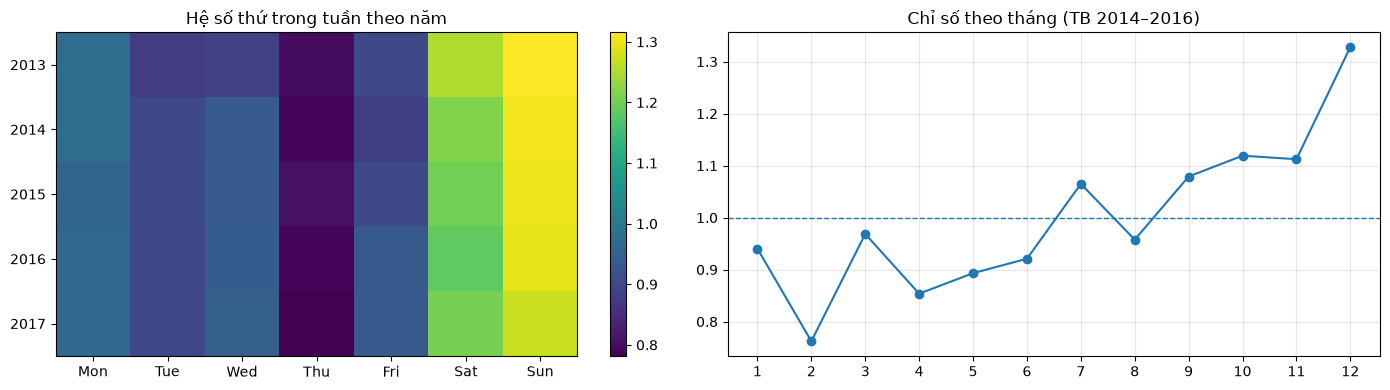

In [61]:
ts = eda["daily"].set_index("date")["sales"].asfreq("D")
ts_c = ts.copy()
ts_c[(ts_c.index.month == 1) & (ts_c.index.day == 1)] = np.nan
log_ts = np.log(ts_c.where(ts_c > 0))
resid = log_ts - log_ts.rolling(28, center=True, min_periods=14).mean()

acf = pd.Series({k: resid.autocorr(lag=k) for k in range(1, 61)})
plt.figure(figsize=(12, 4))
plt.bar(acf.index, acf.values)
for k in range(7, 61, 7):
    plt.axvline(k, linestyle=":", linewidth=0.8, color="red")
plt.title("Tự tương quan của log doanh số đã khử xu hướng (vạch đỏ: bội của 7)"); plt.xlabel("lag (ngày)")
plt.tight_layout(); plt.show()
print("Lag có tự tương quan lớn nhất:", acf.sort_values(ascending=False).head(6).round(3).to_dict())

wk = ts_c.dropna().to_frame("sales")
wk["year"] = wk.index.year; wk["dow"] = wk.index.dayofweek
dow_year = wk.groupby(["year", "dow"])["sales"].mean().unstack("dow")
dow_year = dow_year.div(dow_year.mean(axis=1), axis=0)
dow_year.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][: len(dow_year.columns)]
display(dow_year.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
im = axes[0].imshow(dow_year.values, aspect="auto"); axes[0].set_xticks(range(len(dow_year.columns)), dow_year.columns)
axes[0].set_yticks(range(len(dow_year.index)), dow_year.index); axes[0].set_title("Hệ số thứ trong tuần theo năm"); plt.colorbar(im, ax=axes[0])

monthly = ts_c.resample("MS").sum(min_count=25)
mm = monthly[monthly.index.year.isin([2014, 2015, 2016])].to_frame("sales")
mm["year"] = mm.index.year; mm["month"] = mm.index.month
mm["index"] = mm["sales"] / mm.groupby("year")["sales"].transform("mean")
month_profile = mm.groupby("month")["index"].mean()
axes[1].plot(month_profile.index, month_profile.values, marker="o"); axes[1].axhline(1, linestyle="--", linewidth=1)
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Chỉ số theo tháng (TB 2014–2016)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Các độ trễ có tương quan cao tập trung ở bội của 7, phù hợp với chu kỳ tuần. Hệ số theo thứ khá ổn định giữa các năm.

Khi dự báo nhiều ngày, mọi giá trị lịch sử vẫn phải nằm trước hoặc tại ngày cắt. Không dùng doanh số tuần trước nếu ngày đó đã nằm trong horizon cần dự báo.


## 39. Cơ cấu train và test

Tách cặp đang bán, cặp không bán gần đây và cặp mới. Kiểm tra lịch của 16 ngày test.


In [62]:
pair = eda["pair"]
train_end = eda["daily"]["date"].max()

test_keys = pd.read_csv(RAW_DATA_DIR / "test.csv", usecols=["date", "store_nbr", "item_nbr"],
                        dtype={"date": "string", "store_nbr": "int16", "item_nbr": "int32"})
test_pairs = test_keys[["store_nbr", "item_nbr"]].drop_duplicates()
test_days = test_keys["date"].nunique()

merged = test_pairs.merge(pair[["store_nbr", "item_nbr", "first_date", "last_date", "rows"]],
                          on=["store_nbr", "item_nbr"], how="left", indicator=True)
train_items = set(pair["item_nbr"].unique())
merged["item_known"] = merged["item_nbr"].isin(train_items)

category = np.select(
    [
        (merged["_merge"] == "left_only") & merged["item_known"],
        (merged["_merge"] == "left_only") & ~merged["item_known"],
        merged["last_date"] < train_end - pd.Timedelta(days=27),
    ],
    ["cặp mới, item đã có ở cửa hàng khác", "cặp mới, item chưa từng có (cold-start item)", "cặp cũ, ngừng bán > 28 ngày"],
    default="cặp cũ, có bán trong 28 ngày cuối",
)
merged["category"] = category
summary = merged["category"].value_counts().rename_axis("nhóm").to_frame("số cặp")
summary["tỷ lệ cặp (%)"] = summary["số cặp"] / summary["số cặp"].sum() * 100
summary["số dòng test"] = summary["số cặp"] * test_days
display(summary.round(2))

stale = merged[merged["category"] == "cặp cũ, ngừng bán > 28 ngày"]
if len(stale):
    gap = (train_end - stale["last_date"]).dt.days
    print("Số ngày từ lần bán cuối đến cuối train (cặp ngừng bán) — phân vị 25/50/75:", gap.quantile([0.25, 0.5, 0.75]).tolist())

cal = pd.DataFrame({"date": pd.to_datetime(sorted(test_keys["date"].unique()))})
cal["thứ"] = cal["date"].dt.day_name(); cal["ngày_trong_tháng"] = cal["date"].dt.day
cal["cuối_tháng_(30–31)"] = cal["ngày_trong_tháng"] >= 30
display(cal)

,số cặp,tỷ lệ cặp (%),số dòng test
nhóm,,,
"cặp cũ, có bán trong 28 ngày cuối",149707,71.07,2395312
"cặp mới, item đã có ở cửa hàng khác",41201,19.56,659216
"cặp cũ, ngừng bán > 28 ngày",16506,7.84,264096
"cặp mới, item chưa từng có (cold-start item)",3240,1.54,51840


Số ngày từ lần bán cuối đến cuối train (cặp ngừng bán) — phân vị 25/50/75: [57.0, 121.0, 294.75]


,date,thứ,ngày_trong_tháng,cuối_tháng_(30–31)
0,2017-08-16,Wednesday,16,False
1,2017-08-17,Thursday,17,False
2,2017-08-18,Friday,18,False
3,2017-08-19,Saturday,19,False
4,2017-08-20,Sunday,20,False
5,2017-08-21,Monday,21,False
6,2017-08-22,Tuesday,22,False
7,2017-08-23,Wednesday,23,False
8,2017-08-24,Thursday,24,False
9,2017-08-25,Friday,25,False


Khoảng **71,07%** cặp test có dòng gần đây, **7,84%** không có dòng trong khoảng gần đây, **19,56%** là cặp mới có item đã biết và **1,54%** có item chưa từng xuất hiện.

Gần 29% dòng test không có lịch sử gần đây của chính cặp. Cần xem lỗi theo từng nhóm. Notebook 03 phân loại lại theo doanh số dương tại ngày cắt; số cặp có thể chênh nhẹ so với cách dùng ngày xuất hiện của dòng ở EDA.


## 40. Tương quan sau chênh lệch 7 ngày

Tính tương quan ở mức gốc và sau chênh lệch 7 ngày để giảm ảnh hưởng xu hướng/chu kỳ tuần. Giá dầu được điền tiến cho phần phân tích này.


Tương quan Pearson ở dạng MỨC


,sales,rows,transactions,oil,promo_rate
sales,1.000,0.781,0.703,-0.437,0.345
rows,0.781,1.000,0.337,-0.694,0.653
transactions,0.703,0.337,1.000,-0.184,0.054
oil,-0.437,-0.694,-0.184,1.000,-0.405
promo_rate,0.345,0.653,0.054,-0.405,1.000


Tương quan Pearson ở dạng LOG-CHÊNH LỆCH 7 NGÀY


,sales,rows,transactions,oil,promo_rate
sales,1.000,0.854,0.614,0.076,0.045
rows,0.854,1.000,0.454,0.097,0.107
transactions,0.614,0.454,1.000,-0.001,0.032
oil,0.076,0.097,-0.001,1.000,-0.012
promo_rate,0.045,0.107,0.032,-0.012,1.000


,mức,log-chênh lệch 7 ngày
rows,0.781,0.854
transactions,0.703,0.614
oil,-0.437,0.076
promo_rate,0.345,0.045


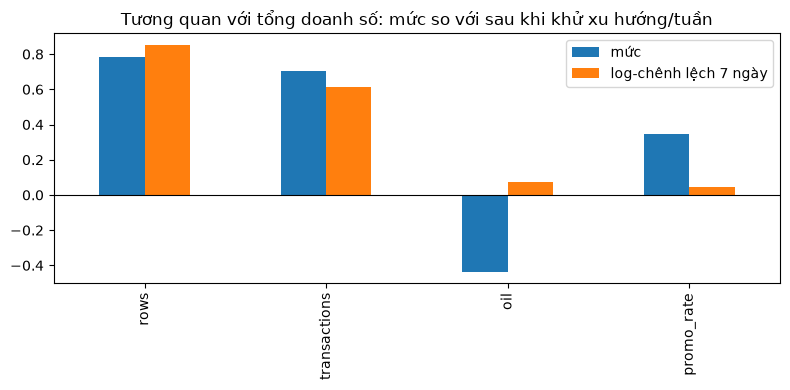

In [63]:
d = eda["daily"].set_index("date")
cal_index = pd.date_range(d.index.min(), d.index.max(), freq="D")

tx = small_tables["transactions.csv"].copy()
tx["date"] = pd.to_datetime(tx["date"])
tx_daily = tx.groupby("date")["transactions"].sum()

oil = small_tables["oil.csv"].copy()
oil["date"] = pd.to_datetime(oil["date"])
oil_series = oil.set_index("date")["dcoilwtico"].reindex(cal_index).ffill()

known = d["promo_true_rows"] + d["promo_false_rows"]
frame = pd.DataFrame({
    "sales": d["sales"].reindex(cal_index),
    "rows": d["rows"].reindex(cal_index),
    "transactions": tx_daily.reindex(cal_index),
    "oil": oil_series,
    "promo_rate": (d["promo_true_rows"] / known.replace(0, np.nan)).reindex(cal_index),
})
closed = (frame.index.month == 1) & (frame.index.day == 1)
frame.loc[closed] = np.nan

levels = frame.dropna()
delta = np.log(frame[["sales", "rows", "transactions", "oil"]].where(frame[["sales", "rows", "transactions", "oil"]] > 0)).diff(7)
delta["promo_rate"] = frame["promo_rate"].diff(7)
delta = delta.dropna()

corr_levels = levels.corr(method="pearson")
corr_delta = delta.corr(method="pearson")
print("Tương quan Pearson ở dạng MỨC"); display(corr_levels.round(3))
print("Tương quan Pearson ở dạng LOG-CHÊNH LỆCH 7 NGÀY"); display(corr_delta.round(3))

compare = pd.DataFrame({"mức": corr_levels["sales"], "log-chênh lệch 7 ngày": corr_delta["sales"]}).drop(index="sales")
display(compare.round(3))
compare.plot(kind="bar", figsize=(8, 4)); plt.axhline(0, color="black", linewidth=0.8)
plt.title("Tương quan với tổng doanh số: mức so với sau khi khử xu hướng/tuần"); plt.tight_layout(); plt.show()

## 41. Heatmap tương quan

Trái: tương quan ở mức gốc. Phải: sau chênh lệch 7 ngày. Đỏ là cùng chiều, xanh là ngược chiều, gần trắng là tương quan yếu.

Hình dùng dữ liệu tổng hợp theo ngày. Tương quan không chứng minh quan hệ nhân quả hoặc chất lượng dự báo ở từng cặp.


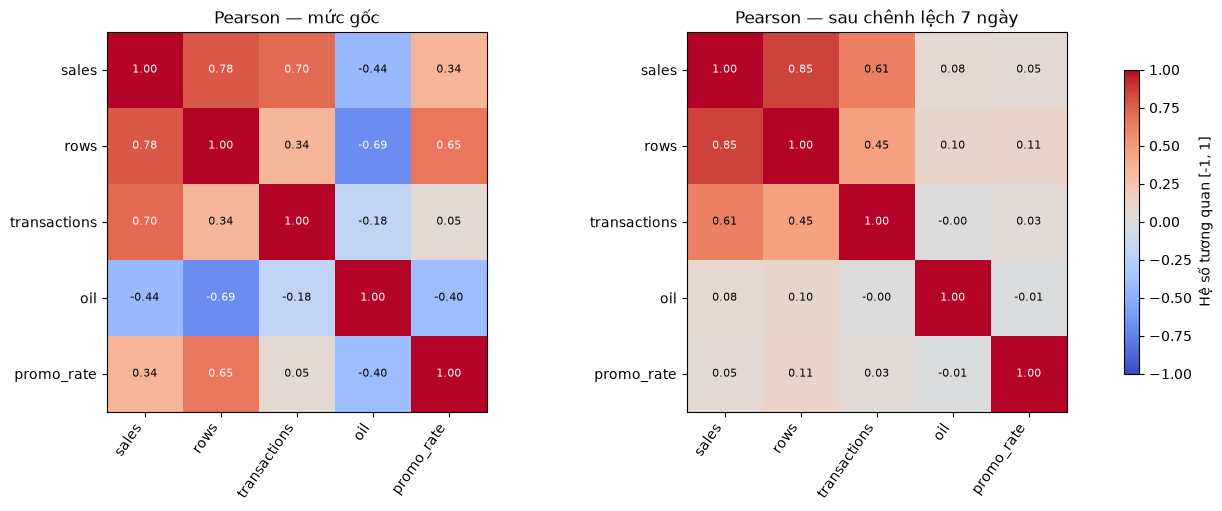

In [64]:
def draw_correlation_heatmap(corr, ax, title):
    values = corr.to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_invalid(values), cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=55, ha='right')
    ax.set_yticks(range(len(corr.index)), labels=corr.index)
    ax.set_title(title)
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            v=values[i,j]
            label=f'{v:.2f}' if np.isfinite(v) else 'NA'
            ax.text(j,i,label,ha='center',va='center',fontsize=8,
                    color='white' if np.isfinite(v) and abs(v)>.65 else 'black')
    return image

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
im = draw_correlation_heatmap(corr_levels, axes[0], 'Pearson — mức gốc')
draw_correlation_heatmap(corr_delta, axes[1], 'Pearson — sau chênh lệch 7 ngày')
fig.colorbar(im, ax=axes, shrink=.8, label='Hệ số tương quan [-1, 1]')
plt.show()


Tương quan dầu với doanh số giảm từ **−0,437 xuống +0,076**. Tương quan của giao dịch giảm từ **0,703 xuống 0,614**, còn số dòng tăng từ **0,781 lên 0,854**.

Kết quả cho thấy xu hướng và độ phủ ảnh hưởng lớn đến tương quan ở mức gốc. Dầu cần được thử riêng trong mô hình; giao dịch chỉ được dùng đến ngày cắt.


## 42. Bộ nhớ khi phân tích

Ghi RAM khả dụng, kích thước train và chunk đang dùng.


In [65]:
if psutil is not None:
    mem = psutil.virtual_memory()
    print(f"Current available RAM: {mem.available / (1024**3):.2f} GB")
    print(f"Current RAM usage: {mem.percent:.1f}%")

largest_file = file_inventory_df.iloc[0]
print(f"Largest raw file: {largest_file['file']}")
print(f"Largest raw file size: {largest_file['size_mb'] / 1024:.2f} GB")
print(f"Working chunk size: {DEFAULT_CHUNK_SIZE:,} rows")

Current available RAM: 1.98 GB
Current RAM usage: 87.4%
Largest raw file: train.csv
Largest raw file size: 4.65 GB
Working chunk size: 100,000 rows


Train không được giả định là vừa RAM. Dùng cache tổng hợp và xử lý từng phần; chỉ đọc toàn bộ các bảng nhỏ.


## 43. Tổng hợp kết quả EDA

Các kết quả dưới đây dùng để kiểm tra cleaning và thiết kế feature.


In [66]:
eda_summary = {
    "raw_files": len(csv_files),
    "train_rows": int(
        shape_df.loc[shape_df["file"] == "train.csv", "rows"].iloc[0]
    ) if "train.csv" in shape_df["file"].values else None,
    "train_date_min": str(train_min) if train_min is not None else None,
    "train_date_max": str(train_max) if train_max is not None else None,
    "target_zero_pct": float(target_summary["zero_pct"]),
    "target_negative_pct": float(target_summary["negative_pct"]),
    "train_duplicate_rows_within_chunks": int(
        train_duplicate_result["duplicate_rows_within_chunks"]
    ),
    "chunk_size": DEFAULT_CHUNK_SIZE,
}

pd.Series(eda_summary)

raw_files                                               8
train_rows                                      125497040
train_date_min                        2013-01-01 00:00:00
train_date_max                        2017-08-15 00:00:00
target_zero_pct                                       0.0
target_negative_pct                              0.006211
train_duplicate_rows_within_chunks                      0
chunk_size                                         100000
dtype: object

## 44. Chất lượng dữ liệu đã kiểm tra

- Train có 125.497.040 dòng; 7.795 dòng âm và không có dòng bằng 0.
- Khuyến mãi thiếu 21.657.651 dòng, tập trung trước tháng 04/2014.
- Giá dầu thiếu 43/1.218 giá trị.
- Các khóa cửa hàng và mặt hàng có metadata tương ứng.
- Bốn ngày thiếu toàn bộ là 25/12 của các năm 2013–2016.
- Notebook 02 kiểm tra đầy đủ hơn về schema, khóa và số dòng đầu ra.


## 45. Đặc điểm thời gian

Có chu kỳ tuần rõ và tín hiệu đầu/cuối tháng. Ngày 15 chưa có mức tăng ổn định. Tháng 12 thường cao; ngày 01/01 rất thấp.

Độ phủ thay đổi theo năm nên tổng doanh số không chỉ phản ánh nhu cầu. Validation dùng cửa sổ 16 ngày và chỉ lấy lịch sử trước ngày cắt.


## 46. Đặc điểm target

Target lệch phải, có số thực và số âm. Cleaning giữ nguyên giá trị; target học dùng `log1p(clip(y, 0))`. Chưa có bằng chứng để tự động xóa mọi cực trị.


## 47. Xử lý ở notebook 02

Chuẩn hóa ngày và kiểu khóa, giữ missing và doanh số âm, kiểm tra số dòng trước/sau. Không thêm dòng vắng, không điền giá dầu và không sửa raw trong cleaning.


## 48. Nội dung cần theo dõi khi tạo feature

| Nội dung | Cần theo dõi |
|---|---|
| Ngày không có dòng | Không bán, chưa hoạt động hoặc không niêm yết |
| Khuyến mãi | Thiếu theo giai đoạn và khác cách quan sát giữa train/test |
| Lịch sử cặp | Mức bán, tần suất và trung bình cùng thứ |
| Cặp mới | Dùng metadata/phân cấp và đánh giá riêng |
| Giá dầu, giao dịch | Chỉ dùng giá trị đã biết tại ngày cắt |
| Ngày lễ | Ghép đúng phạm vi, không nhân bản dòng |


## 49. Phạm vi kiểm tra ở các bước sau

Notebook 03 tạo feature theo từng mốc để giữ đúng thời gian và giới hạn RAM. Notebook 04 tính baseline. Notebook 05 so sánh model trên cùng fold.

Chưa kiểm chứng đầy đủ cách xử lý ngày vắng, chất lượng cặp mới và mức đóng góp của từng nhóm feature. Các phần này cần được báo cáo riêng khi đánh giá.


## 50. Kết quả

Dữ liệu đủ để tiếp tục cleaning và tạo feature. Các điểm cần giữ trong phân tích là train thưa, khuyến mãi thiếu theo thời gian, độ phủ thay đổi và cặp mới của test.
